# Notebook 13 — Análise ΔPA no PulseDB: existe sinal intra-sujeito recuperável?

**Pergunta.** Nos notebooks anteriores (03, 05, 06, 11) a calibração personalizada mostrou-se
*algebricamente degenerada* no PTT-PPG: como a PA de referência é constante dentro de cada
registro, a variância do alvo no conjunto de ajuste é zero, o slope OLS é forçado a zero e a
"calibração" reduz-se a repetir a leitura de repouso do sujeito. Este notebook testa se o
**PulseDB** — cuja PA vem de ABP quase contínua e portanto **varia dentro do sujeito** —
permite responder à pergunta que o PTT-PPG não permite:

> Existe variação de PA intra-sujeito recuperável a partir do sinal PPG?

**Desenho.** Em vez de prever a PA absoluta (que deixa o modelo vencer apenas identificando o
sujeito), prevemos o **desvio ΔPA** em relação à referência de calibração do próprio sujeito.
O baseline obrigatório é "prever a média de calibração do sujeito", equivalente a ΔPA = 0.

**Escopo dos dados.** O arquivo `_features_pulsedb_calbased_test.csv` foi extraído de
`VitalDB_CalBased_Test_Subset.mat`. Todos os 1.293 sujeitos têm ID no padrão `vp######_#`
e **provêm exclusivamente do VitalDB (população cirúrgica)**. A redistribuição do Kaggle
utilizada não inclui a metade MIMIC-III do PulseDB, de modo que **não há dados de UTI** aqui
e nenhuma estratificação cirúrgico-vs-UTI é possível.

**Base de dados.** Usa `_features_pulsedb_calbased_test_v3.csv`, produzido pelo
**Notebook 14** com a segmentação corrigida (vale-a-vale). A extração anterior recortava o
ciclo entre picos sistólicos, o que punha o pico na borda e degenerava 21 das 41 features.
A tabela final compara os resultados nas duas extrações.

**Consolidação.** Este notebook reúne análises previamente desenvolvidas e validadas, com todas
as verificações de robustez. Nenhum experimento novo é introduzido.

## 0. Importações e configuração

In [1]:
import os
import json
import socket
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

from sklearn.model_selection import KFold, LeaveOneGroupOut
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
np.random.seed(42)

# Figuras com fundo branco e 300 DPI (padrao do relatorio)
plt.rcParams["figure.facecolor"]  = "white"
plt.rcParams["axes.facecolor"]    = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.dpi"]       = 300

print("Computador:", socket.gethostname())
print("Inicio:", datetime.now().strftime("%d/%m/%Y %H:%M:%S"))
import sklearn; print("sklearn:", sklearn.__version__, "| pandas:", pd.__version__)

Computador: NtebookLeticia
Inicio: 04/08/2026 16:08:06
sklearn: 1.9.0 | pandas: 3.0.3


### Caminhos e parâmetros globais

In [2]:
# ─── Raiz unica do projeto (mesma usada nos demais notebooks) ───
BASE_IC            = Path(r"C:\IC_PPG")
PASTA_DADOS        = BASE_IC / "Datasets" / "PTT_PPG"
PASTA_PULSEDB_FEAT = BASE_IC / "Datasets" / "PulseDB_features"
PASTA_FIGS         = BASE_IC / "Figuras_Geradas"
PASTA_FIGS.mkdir(parents=True, exist_ok=True)

# ─── Entradas ───
ARQ_PULSEDB = PASTA_PULSEDB_FEAT / "_features_pulsedb_calbased_test_v3.csv"  # extracao corrigida (NB14)
ARQ_PTTPPG  = PASTA_DADOS / "_features_v2_clean.csv"                      # PTT-PPG v2 (auditoria de variancia, Secao 2)
ARQ_PTTPPG_V3 = PASTA_DADOS / "_features_v3_clean.csv"                    # PTT-PPG v3 corrigido (NB15) — contraste da Secao 6
ARQ_CONFIG  = PASTA_DADOS / "_configuracoes_modelos.json"                 # lista da Versao C

# ─── Prefixo dos artefatos gerados por este notebook ───
PREFIXO = "_nb13_"

# ─── Parametros do protocolo ───
N_CAL       = 20     # segmentos iniciais de cada sujeito usados para CALIBRAR
N_SPLITS    = 5      # folds da validacao cruzada (particao POR SUJEITO)
SEED        = 42     # semente unica de todo o notebook
N_BOOT      = 2000   # reamostragens do bootstrap agrupado por sujeito
N_PERM      = 1000   # permutacoes do controle negativo (item 8.1)
ALPHAS      = np.logspace(-3, 3, 13)   # grade de regularizacao do Ridge

for p in [ARQ_PULSEDB, ARQ_PTTPPG, ARQ_PTTPPG_V3, ARQ_CONFIG]:
    print(f"{'OK ' if p.exists() else 'FALTA '} {p.name}  "
          f"({p.stat().st_size/1e6:.1f} MB)" if p.exists() else f"FALTA {p}")
print(f"\nArtefatos CSV  -> {PASTA_PULSEDB_FEAT}  (prefixo '{PREFIXO}')")
print(f"Figuras (300dpi) -> {PASTA_FIGS}")

OK  _features_pulsedb_calbased_test_v3.csv  (346.7 MB)
OK  _features_v2_clean.csv  (19.9 MB)
OK  _features_v3_clean.csv  (23.9 MB)
OK  _configuracoes_modelos.json  (0.0 MB)

Artefatos CSV  -> C:\IC_PPG\Datasets\PulseDB_features  (prefixo '_nb13_')
Figuras (300dpi) -> C:\IC_PPG\Figuras_Geradas


## 1. Carga e caracterização da amostra

O arquivo tem 62 colunas: as **41 primeiras são as features do sinal PPG**, seguidas de
metadados, rótulos de PA, demografia e as predições já salvas pelo Notebook 09.

Ponto central do desenho: a PA de referência é **constante dentro de cada segmento**
(`record`). Portanto o **segmento é a unidade de observação**, não o ciclo — usar ciclos
inflaria o *n* por um fator de ~11 sem acrescentar informação (pseudorreplicação).
Por isso agregamos as features pela média dos ciclos de cada segmento.

In [3]:
# As 41 primeiras colunas sao as features do sinal; o resto e metadado/rotulo
COLUNAS = pd.read_csv(ARQ_PULSEDB, nrows=0).columns.tolist()
FEATS   = COLUNAS[:41]
META    = ["record", "subject", "bp_sys_mean", "bp_dia_mean"]
print(f"{len(COLUNAS)} colunas | {len(FEATS)} features de sinal")
print("metadados:", COLUNAS[41:])

# Leitura em blocos (arquivo de ~360 MB) ja agregando por segmento, para poupar memoria
blocos = []
for bloco in pd.read_csv(ARQ_PULSEDB, usecols=FEATS + META,
                         dtype={c: "float32" for c in FEATS}, chunksize=120_000):
    blocos.append(bloco.groupby(["subject", "record"], as_index=False).agg(
        {**{f: "mean" for f in FEATS}, "bp_sys_mean": "first", "bp_dia_mean": "first"}))

# Segunda agregacao: junta segmentos partidos na fronteira entre blocos
seg = pd.concat(blocos, ignore_index=True).groupby(["subject", "record"], as_index=False).agg(
    {**{f: "mean" for f in FEATS}, "bp_sys_mean": "first", "bp_dia_mean": "first"})
seg = (seg.replace([np.inf, -np.inf], np.nan)
          .dropna(subset=FEATS)
          .sort_values(["subject", "record"])
          .reset_index(drop=True))

# 'ordem' = posicao temporal do segmento dentro do sujeito (0, 1, 2, ...)
seg["ordem"] = seg.groupby("subject").cumcount()
seg["n_seg"] = seg.groupby("subject")["ordem"].transform("max") + 1

N_SEGMENTOS = len(seg)
N_SUJEITOS  = seg.subject.nunique()
print(f"\n{N_SEGMENTOS} segmentos | {N_SUJEITOS} sujeitos")
print(f"segmentos por sujeito: mediana={seg.groupby('subject').size().median():.0f} "
      f"| min={seg.groupby('subject').size().min()} "
      f"| max={seg.groupby('subject').size().max()}")

58 colunas | 41 features de sinal
metadados: ['weight', 'record', 'subject', 'condition', 'cycle_idx', 'peak_sample', 'time_s', 'bp_sys_start', 'bp_sys_end', 'bp_dia_start', 'bp_dia_end', 'bp_sys_mean', 'bp_dia_mean', 'age', 'gender', 'height', 'weight.1']



51720 segmentos | 1293 sujeitos
segmentos por sujeito: mediana=40 | min=40 | max=40


### 1.1 Verificação da origem dos sujeitos e demografia

In [4]:
import re, collections

# Todos os IDs seguem o MESMO padrao? (verificacao de populacao unica)
padroes = collections.Counter(re.sub(r"\d", "#", s) for s in seg.subject.unique())
print("Padroes de ID de sujeito (digitos substituidos por '#'):")
for p, n in padroes.most_common():
    print(f"   {p:<16s} {n} sujeitos ({100*n/N_SUJEITOS:.1f}%)")
print("Exemplos:", sorted(seg.subject.unique())[:3], "...", sorted(seg.subject.unique())[-2:])
print("\n=> populacao UNICA: VitalDB (cirurgica). Nao ha MIMIC-III neste arquivo.")

# Demografia: uma linha por sujeito
demo = (pd.read_csv(ARQ_PULSEDB, usecols=["subject", "age", "gender", "height", "weight"])
          .groupby("subject").first())
demo["imc"] = demo.weight / (demo.height / 100) ** 2
print(f"\nDEMOGRAFIA ({len(demo)} sujeitos)")
print(f"  idade : mediana={demo.age.median():.0f} anos "
      f"[{demo.age.min():.0f}-{demo.age.max():.0f}] | faltantes={demo.age.isna().sum()}")
print(f"          ATENCAO: {int((demo.age == 0).sum())} sujeitos com idade = 0 "
      f"(verificar se e pediatrico real ou faltante codificado como zero)")
print(f"  sexo  : {dict(demo.gender.value_counts(dropna=False))}")
print(f"  altura: mediana={demo.height.median():.1f} cm | peso: mediana={demo.weight.median():.1f} kg")
print(f"  IMC   : mediana={demo.imc.median():.1f} [q25={demo.imc.quantile(.25):.1f}, "
      f"q75={demo.imc.quantile(.75):.1f}]")

demo.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}demografia.csv")
print(f"\n[salvo] {PREFIXO}demografia.csv")

Padroes de ID de sujeito (digitos substituidos por '#'):
   vp######_#       1293 sujeitos (100.0%)
Exemplos: ['vp000001_1', 'vp000003_1', 'vp000005_1'] ... ['vp006084_1', 'vp006090_1']

=> populacao UNICA: VitalDB (cirurgica). Nao ha MIMIC-III neste arquivo.



DEMOGRAFIA (1293 sujeitos)
  idade : mediana=61 anos [0-92] | faltantes=0
          ATENCAO: 0 sujeitos com idade = 0 (verificar se e pediatrico real ou faltante codificado como zero)
  sexo  : {'M': 746, 'F': 547}
  altura: mediana=162.9 cm | peso: mediana=59.9 kg
  IMC   : mediana=22.8 [q25=20.7, q75=25.0]

[salvo] _nb13_demografia.csv


## 2. Auditoria de variância do rótulo — PulseDB vs PTT-PPG

Esta é a auditoria que justifica todo o resto. No PTT-PPG a PA de referência assume **3 valores
por sujeito** (um por condição: sit/walk/run), com desvio intra-sujeito de ~2 a 2,5 mmHg (2,07 PAD; 2,51 PAS na tabela abaixo). Se a
variação intra-sujeito é desprezível frente à variação entre sujeitos, não há alvo para
regredir e qualquer "calibração" degenera.

Reportamos, para cada base: desvio-padrão e faixa intra-sujeito, variância entre e intra
sujeitos, e o **ICC** (fração da variância total que é *entre* sujeitos). ICC alto significa
que conhecer o sujeito já resolve quase tudo — situação em que a calibração entrega a resposta.

In [5]:
def resumo_variancia(df, col_sujeito, col_pas, col_pad, rotulo):
    """Estrutura de variancia intra vs entre sujeitos, no nivel da unidade de observacao."""
    linhas = []
    for col, nome in [(col_pas, "PAS"), (col_pad, "PAD")]:
        g     = df.groupby(col_sujeito)[col]
        sd    = g.std(ddof=1).dropna()             # desvio intra-sujeito
        faixa = (g.max() - g.min()).dropna()       # amplitude intra-sujeito
        entre = g.mean().var(ddof=1)               # variancia das medias dos sujeitos
        intra = (sd ** 2).mean()                   # variancia media dentro dos sujeitos
        linhas.append({
            "base": rotulo, "alvo": nome, "n_sujeitos": int(df[col_sujeito].nunique()),
            "sd_intra_mediana": sd.median(), "sd_intra_media": sd.mean(),
            "faixa_mediana": faixa.median(), "faixa_media": faixa.mean(),
            "var_entre": entre, "var_intra": intra, "ICC": entre / (entre + intra),
            "sujeitos_sd_menor_1": int((sd < 1).sum()),
        })
    return pd.DataFrame(linhas)

# --- PulseDB: unidade = segmento ---
var_pulse = resumo_variancia(seg, "subject", "bp_sys_mean", "bp_dia_mean", "PulseDB (VitalDB)")

# --- PTT-PPG: unidade = (sujeito, condicao), equivalente ao segmento ---
# A auditoria usa a extracao CORRIGIDA v3 (_features_v3_clean.csv, NB15) — a mesma base
# primaria da Secao 6. A extracao antiga v2 degenerava 21 features (razoes de sistole/
# diastole com NaN complementar): o dropna(subset=as 41) zerava 9 combos sujeito x condicao
# e deixava so 57 unidades, embora rotuladas como "22 sujeitos". A v3 recupera os 66 (22 x 3).
COLS_PTT = pd.read_csv(ARQ_PTTPPG, nrows=0).columns.tolist()[:41]

# v2 (extracao antiga) — mantida apenas para o contraste v2 da Secao 6 (res_ptt_v2)
ptt = pd.read_csv(ARQ_PTTPPG, usecols=COLS_PTT + ["subject", "condition",
                                                  "bp_sys_mean", "bp_dia_mean"])
ptt = ptt.replace([np.inf, -np.inf], np.nan).dropna(subset=COLS_PTT)
ptt_seg = ptt.groupby(["subject", "condition"], as_index=False).agg(
    {**{f: "mean" for f in COLS_PTT}, "bp_sys_mean": "first", "bp_dia_mean": "first"})

# v3 (extracao corrigida, NB15) — base da auditoria de variancia
ptt_v3 = pd.read_csv(ARQ_PTTPPG_V3, usecols=COLS_PTT + ["subject", "condition",
                                                        "bp_sys_mean", "bp_dia_mean"])
ptt_v3 = ptt_v3.replace([np.inf, -np.inf], np.nan).dropna(subset=COLS_PTT)
ptt_seg_v3 = ptt_v3.groupby(["subject", "condition"], as_index=False).agg(
    {**{f: "mean" for f in COLS_PTT}, "bp_sys_mean": "first", "bp_dia_mean": "first"})

var_ptt = resumo_variancia(ptt_seg_v3, "subject", "bp_sys_mean", "bp_dia_mean", "PTT-PPG")
print(f"[PTT-PPG] auditoria sobre v3 (extracao corrigida): {len(ptt_seg_v3)} unidades "
      f"(sujeito x condicao) | {ptt_seg_v3.subject.nunique()} sujeitos "
      f"(v2 antiga: {len(ptt_seg)} unidades)")

var_comp = pd.concat([var_ptt, var_pulse], ignore_index=True)
print(var_comp.to_string(index=False, float_format=lambda v: f"{v:9.3f}"))

print("\nRAZAO PulseDB / PTT-PPG (o quanto ha mais variacao intra-sujeito aqui):")
for alvo in ["PAS", "PAD"]:
    a = var_ptt[var_ptt.alvo == alvo].iloc[0]
    b = var_pulse[var_pulse.alvo == alvo].iloc[0]
    print(f"  {alvo}: SD intra {a.sd_intra_media:.2f} -> {b.sd_intra_media:.2f} mmHg "
          f"({b.sd_intra_media/a.sd_intra_media:.1f}x) | "
          f"faixa {a.faixa_mediana:.2f} -> {b.faixa_mediana:.2f} mmHg "
          f"({b.faixa_mediana/a.faixa_mediana:.1f}x) | "
          f"ICC {a.ICC:.3f} -> {b.ICC:.3f}")

var_comp.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}auditoria_variancia.csv", index=False)
print(f"\n[salvo] {PREFIXO}auditoria_variancia.csv")

[PTT-PPG] auditoria sobre v3 (extracao corrigida): 66 unidades (sujeito x condicao) | 22 sujeitos (v2 antiga: 57 unidades)
             base alvo  n_sujeitos  sd_intra_mediana  sd_intra_media  faixa_mediana  faixa_media  var_entre  var_intra       ICC  sujeitos_sd_menor_1
          PTT-PPG  PAS          22             2.504           2.738          4.750        5.182    171.086     10.538     0.942                    2
          PTT-PPG  PAD          22             2.131           2.363          4.000        4.568     68.930      8.098     0.895                    2
PulseDB (VitalDB)  PAS        1293            12.987          13.672         54.674       57.964    151.033    209.514     0.419                    0
PulseDB (VitalDB)  PAD        1293             7.123           7.453         30.256       32.362     84.225     63.108     0.572                    0

RAZAO PulseDB / PTT-PPG (o quanto ha mais variacao intra-sujeito aqui):
  PAS: SD intra 2.74 -> 13.67 mmHg (5.0x) | faixa 4.75

### Figura 1 — Estrutura de variância nas duas bases

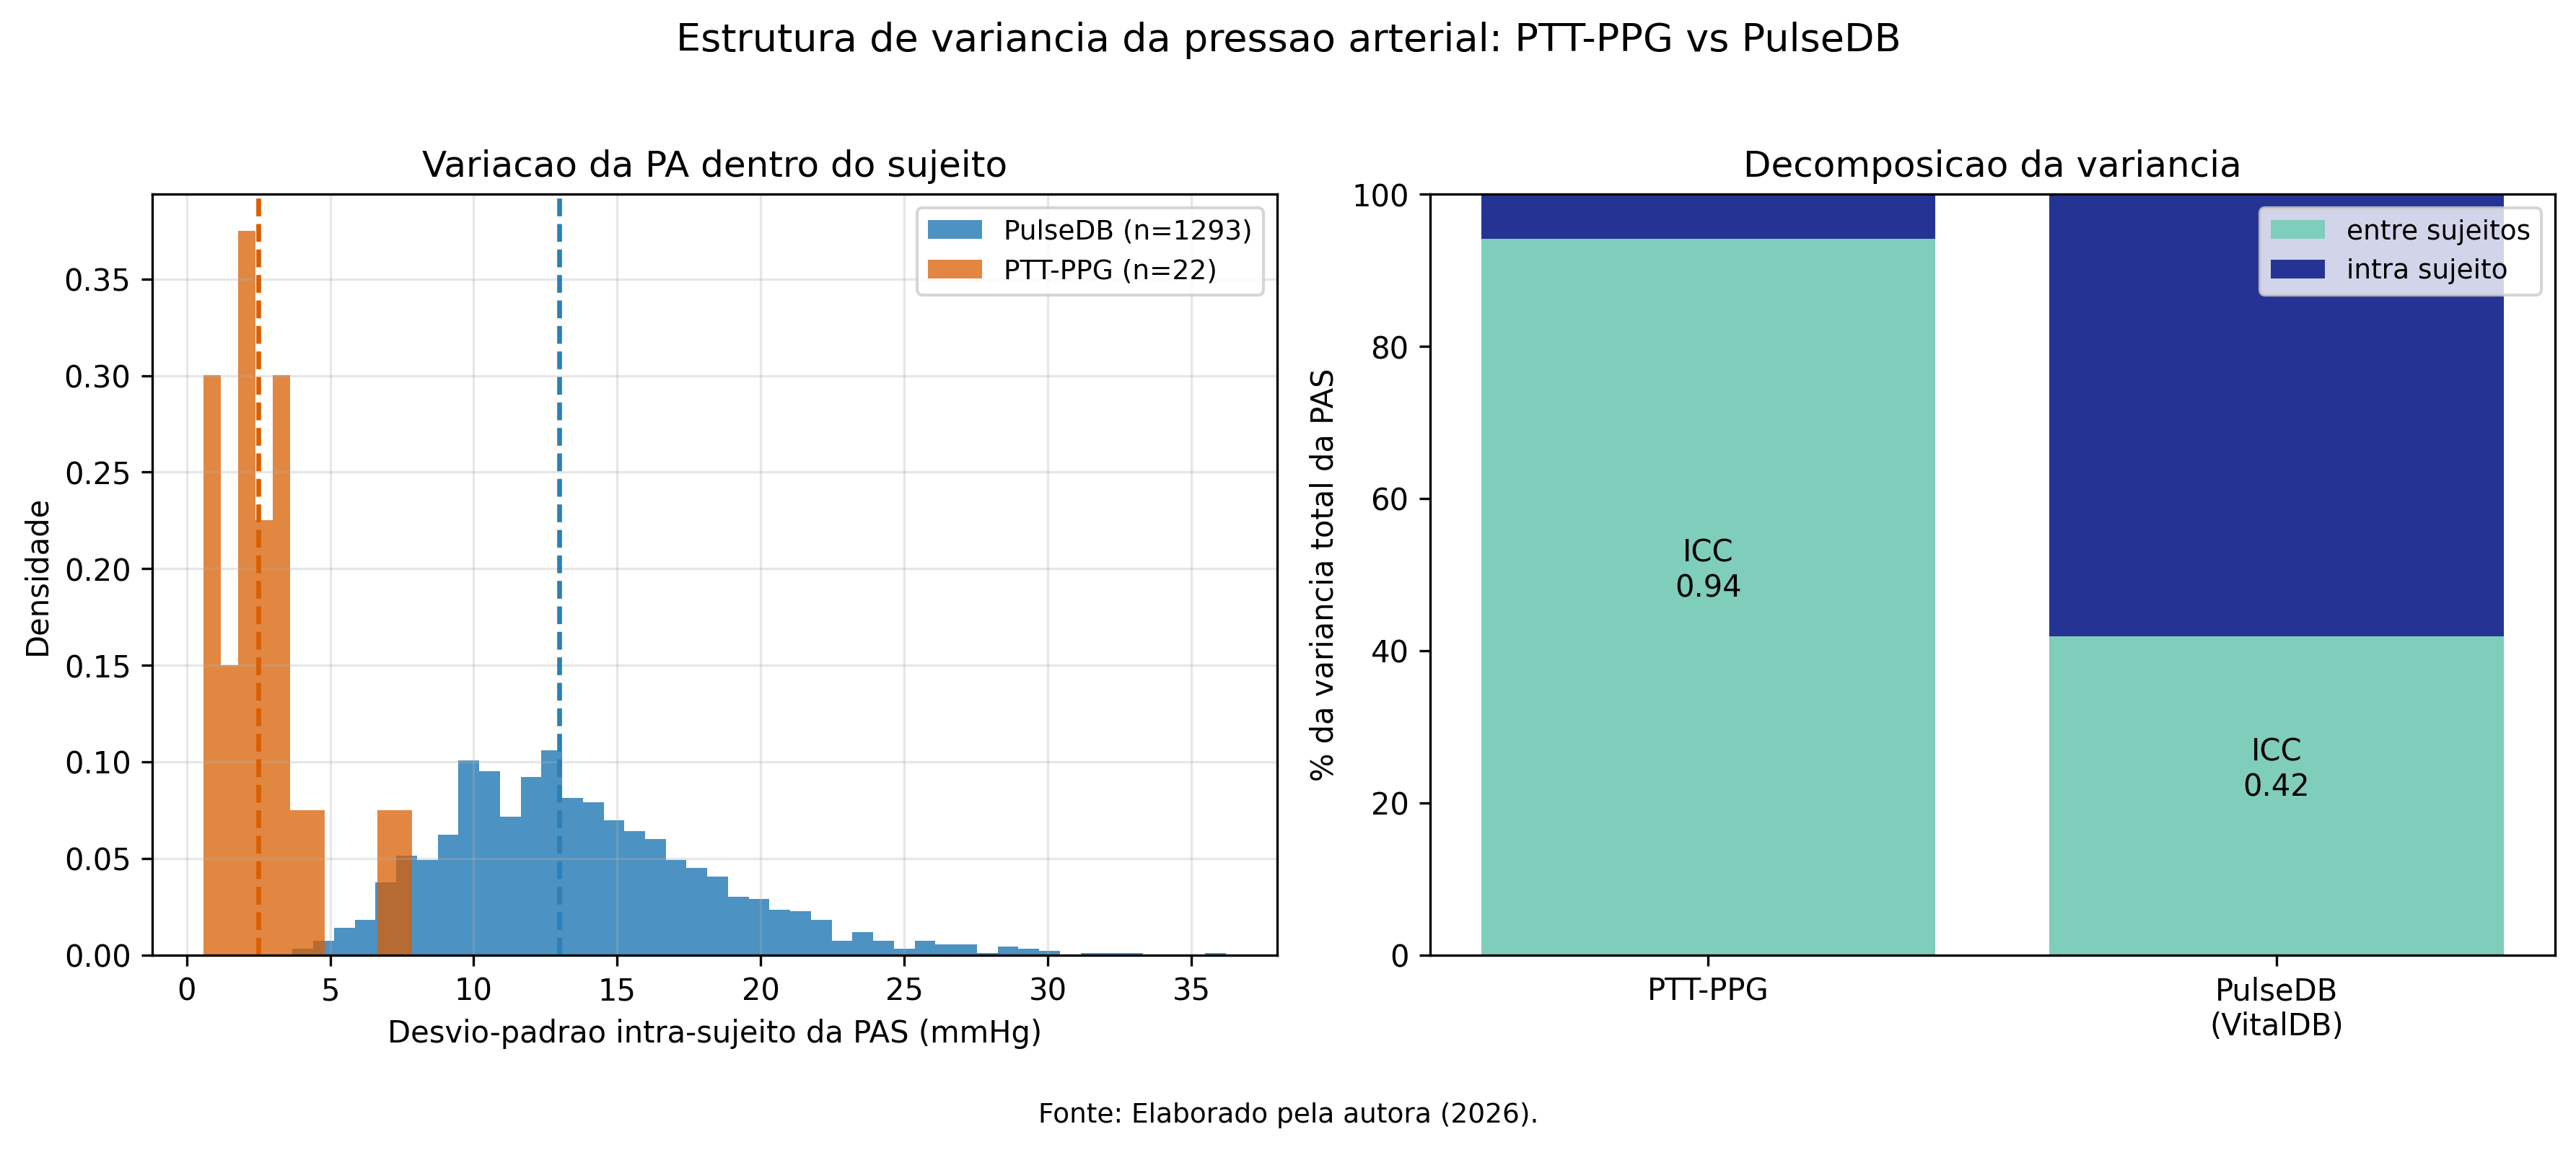

[figura] NB13_variancia_intra_sujeito.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sd_p = seg.groupby("subject")["bp_sys_mean"].std(ddof=1).dropna()
sd_t = ptt_seg_v3.groupby("subject")["bp_sys_mean"].std(ddof=1).dropna()

ax = axes[0]
ax.hist(sd_p, bins=45, color="#2c7fb8", alpha=.85, label=f"PulseDB (n={len(sd_p)})", density=True)
ax.hist(sd_t, bins=12, color="#d95f02", alpha=.75, label=f"PTT-PPG (n={len(sd_t)})", density=True)
ax.axvline(sd_p.median(), color="#2c7fb8", ls="--", lw=1.6)
ax.axvline(sd_t.median(), color="#d95f02", ls="--", lw=1.6)
ax.set_xlabel("Desvio-padrao intra-sujeito da PAS (mmHg)")
ax.set_ylabel("Densidade"); ax.set_title("Variacao da PA dentro do sujeito")
ax.legend(fontsize=9); ax.grid(alpha=.3)

ax = axes[1]
bases = ["PTT-PPG", "PulseDB\n(VitalDB)"]
entre = [var_ptt[var_ptt.alvo == "PAS"].var_entre.iloc[0],
         var_pulse[var_pulse.alvo == "PAS"].var_entre.iloc[0]]
intra = [var_ptt[var_ptt.alvo == "PAS"].var_intra.iloc[0],
         var_pulse[var_pulse.alvo == "PAS"].var_intra.iloc[0]]
tot = [e + i for e, i in zip(entre, intra)]
ax.bar(bases, [100*e/t for e, t in zip(entre, tot)], color="#7fcdbb", label="entre sujeitos")
ax.bar(bases, [100*i/t for i, t in zip(intra, tot)],
       bottom=[100*e/t for e, t in zip(entre, tot)], color="#253494", label="intra sujeito")
for k, (e, t) in enumerate(zip(entre, tot)):
    ax.text(k, 100*e/t/2, f"ICC\n{e/t:.2f}", ha="center", color="black", fontsize=10)
ax.set_ylabel("% da variancia total da PAS"); ax.set_ylim(0, 100)
ax.set_title("Decomposicao da variancia"); ax.legend(fontsize=9)

fig.suptitle("Estrutura de variancia da pressao arterial: PTT-PPG vs PulseDB", y=1.02, fontsize=13)
fig.text(0.5, -0.04, "Fonte: Elaborado pela autora (2026).", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(PASTA_FIGS / "NB13_variancia_intra_sujeito.png", dpi=300, bbox_inches="tight")
plt.show()
print("[figura] NB13_variancia_intra_sujeito.png")

## 3. Regressão within/Δ — protocolo de implantação  ★ RESULTADO PRINCIPAL

**Este é o resultado que deve ser citado.** O desenho reproduz o uso real do sistema e não
contém vazamento algum:

| | |
|---|---|
| Calibração | primeiros **20 segmentos** de cada sujeito |
| Teste | últimos 20 segmentos do mesmo sujeito |
| Centralização | médias de features **e** de PA vindas **somente** da calibração |
| Modelo | treinado em **outros** sujeitos (partição por sujeito, 5 folds) |
| Alvo | ΔPA = PA do segmento − média de calibração do sujeito |
| Baseline | prever ΔPA = 0, isto é, repetir a média de calibração |

O baseline é o que qualquer sistema calibrado já entrega de graça. Só interessa o que o supera.

In [7]:
def monta_within(n_cal=N_CAL, gap=0, feats=None, inverter=False):
    """Constroi as matrizes do protocolo de implantacao.

    n_cal    : quantos segmentos iniciais de cada sujeito calibram
    gap      : segmentos descartados entre calibracao e teste (item 8.3)
    feats    : subconjunto de features (None = todas as 41)
    inverter : espelha a ordem temporal (controle do item 8.3)

    Devolve dicionario com X/y de treino e teste e os vetores de sujeito.
    IMPORTANTE: as medias de centralizacao vem SO dos segmentos de calibracao.
    """
    fs = FEATS if feats is None else feats
    d = seg.copy()
    if inverter:
        d["ordem"] = d["n_seg"] - 1 - d["ordem"]

    cal = d[d.ordem < n_cal]                 # bloco de calibracao
    tst = d[d.ordem >= n_cal + gap]          # bloco de teste (apos o gap)

    media_feat = cal.groupby("subject")[fs].mean()          # <- so calibracao
    media_pas  = cal.groupby("subject")["bp_sys_mean"].mean()
    media_pad  = cal.groupby("subject")["bp_dia_mean"].mean()

    gc = cal.groupby("subject")
    out = {
        "Xtr": cal[fs].values - gc[fs].transform("mean").values,
        "Xte": tst[fs].values - media_feat.loc[tst.subject].values,
        "ytr": {"PAS": (cal.bp_sys_mean - gc.bp_sys_mean.transform("mean")).values,
                "PAD": (cal.bp_dia_mean - gc.bp_dia_mean.transform("mean")).values},
        "yte": {"PAS": (tst.bp_sys_mean - media_pas.loc[tst.subject].values).values,
                "PAD": (tst.bp_dia_mean - media_pad.loc[tst.subject].values).values},
        "gtr": cal.subject.values, "gte": tst.subject.values,
        "ordem_te": tst.ordem.values, "n_cal": n_cal, "feats": fs,
    }
    return out


def valida_por_sujeito(dados, alvo, modelo="ridge"):
    """Validacao cruzada com particao POR SUJEITO (KFold sobre a lista de sujeitos).

    Usamos KFold sobre np.unique(sujeitos) em vez de GroupKFold porque o algoritmo de
    atribuicao do GroupKFold mudou entre versoes do scikit-learn (1.8 -> 1.9), tornando
    o resultado nao reprodutivel. Esta forma e deterministica e garante, por construcao,
    que nenhum sujeito aparece simultaneamente em treino e teste.
    """
    Xtr, Xte = dados["Xtr"], dados["Xte"]
    ytr, yte = dados["ytr"][alvo], dados["yte"][alvo]
    gtr, gte = dados["gtr"], dados["gte"]
    sujeitos = np.unique(gtr)

    pred, fold = np.zeros(len(yte)), np.full(len(yte), -1)
    coefs, alphas_sel = [], []
    for k, (i_tr, i_te) in enumerate(KFold(N_SPLITS, shuffle=True,
                                           random_state=SEED).split(sujeitos), 1):
        m_tr = np.isin(gtr, sujeitos[i_tr])
        m_te = np.isin(gte, sujeitos[i_te])
        assert not (set(gtr[m_tr]) & set(gte[m_te])), "sujeito em treino E teste!"
        if modelo == "ridge":
            sc = StandardScaler().fit(Xtr[m_tr])          # scaler so no treino
            mdl = RidgeCV(alphas=ALPHAS).fit(sc.transform(Xtr[m_tr]), ytr[m_tr])
            pred[m_te] = mdl.predict(sc.transform(Xte[m_te]))
            coefs.append(pd.Series(mdl.coef_, index=dados["feats"]))
            alphas_sel.append(mdl.alpha_)
        else:
            mdl = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                        n_jobs=-1, random_state=SEED).fit(Xtr[m_tr], ytr[m_tr])
            pred[m_te] = mdl.predict(Xte[m_te])
        fold[m_te] = k
    assert (fold > 0).all(), "algum segmento de teste ficou sem predicao"
    return {"y": yte, "pred": pred, "fold": fold, "grupo": gte,
            "coefs": coefs, "alphas": alphas_sel}


def metricas(y, p):
    """MAE, RMSE, R2, erro medio (ME) e desvio do erro (SD)."""
    e = y - p
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": float(np.sqrt(mean_squared_error(y, p))),
            "R2": r2_score(y, p), "ME": float(e.mean()),
            "SD": float(e.std(ddof=1)), "n": int(len(y))}


def bootstrap_por_sujeito(y, p, grupos, n_boot=N_BOOT, seed=SEED):
    """IC 95% reamostrando SUJEITOS INTEIROS (cluster bootstrap).

    Necessario porque os segmentos de um mesmo sujeito nao sao independentes;
    reamostrar segmentos daria intervalos artificialmente estreitos.
    """
    rng = np.random.default_rng(seed)
    unicos = np.unique(grupos)
    indices = {s: np.where(grupos == s)[0] for s in unicos}
    r2s, maes = [], []
    for _ in range(n_boot):
        sel = np.concatenate([indices[s] for s in rng.choice(unicos, len(unicos), replace=True)])
        r2s.append(r2_score(y[sel], p[sel]))
        maes.append(mean_absolute_error(y[sel], p[sel]))
    return (np.percentile(r2s, [2.5, 97.5]), np.percentile(maes, [2.5, 97.5]))


print("Funcoes do protocolo definidas.")

Funcoes do protocolo definidas.


In [8]:
# ─── RESULTADO PRINCIPAL ───
dados_impl = monta_within()
print(f"Calibracao: {len(dados_impl['Xtr'])} segmentos | Teste: {len(dados_impl['Xte'])} segmentos")
print(f"Sujeitos: {len(np.unique(dados_impl['gtr']))}")
print(f"SD(DeltaPAS)={dados_impl['yte']['PAS'].std():.2f} | "
      f"SD(DeltaPAD)={dados_impl['yte']['PAD'].std():.2f} mmHg\n")

linhas_principal, resultados_impl = [], {}
for alvo in ["PAS", "PAD"]:
    yte = dados_impl["yte"][alvo]
    gte = dados_impl["gte"]

    # baseline: prever Delta = 0 (repetir a media de calibracao do sujeito)
    base = np.zeros(len(yte))
    m = metricas(yte, base); (r2ic, maeic) = bootstrap_por_sujeito(yte, base, gte)
    linhas_principal.append({"alvo": alvo, "modelo": "BASELINE (media de calibracao)", **m,
                             "R2_lo": r2ic[0], "R2_hi": r2ic[1],
                             "MAE_lo": maeic[0], "MAE_hi": maeic[1]})

    for nome, tag in [("Within LINEAR (Ridge)", "ridge"), ("Within RANDOM FOREST", "rf")]:
        r = valida_por_sujeito(dados_impl, alvo, modelo=tag)
        resultados_impl[(alvo, tag)] = r
        m = metricas(r["y"], r["pred"])
        (r2ic, maeic) = bootstrap_por_sujeito(r["y"], r["pred"], r["grupo"])
        linhas_principal.append({"alvo": alvo, "modelo": nome, **m,
                                 "R2_lo": r2ic[0], "R2_hi": r2ic[1],
                                 "MAE_lo": maeic[0], "MAE_hi": maeic[1]})

res_principal = pd.DataFrame(linhas_principal)
for alvo in ["PAS", "PAD"]:
    print(f"--- Delta{alvo} (n={int(res_principal[res_principal.alvo==alvo].n.iloc[0])} segmentos, "
          f"{len(np.unique(dados_impl['gte']))} sujeitos) ---")
    print(f"  {'modelo':<32s}{'R2':>9s}{'IC95 R2':>20s}{'MAE':>9s}{'IC95 MAE':>18s}")
    for _, x in res_principal[res_principal.alvo == alvo].iterrows():
        print(f"  {x.modelo:<32s}{x.R2:>9.4f}  [{x.R2_lo:>6.4f},{x.R2_hi:>6.4f}]"
              f"{x.MAE:>9.4f}  [{x.MAE_lo:>6.3f},{x.MAE_hi:>6.3f}]")
    print()

res_principal.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}resultado_principal.csv", index=False)
print(f"[salvo] {PREFIXO}resultado_principal.csv")

Calibracao: 25860 segmentos | Teste: 25860 segmentos
Sujeitos: 1293
SD(DeltaPAS)=16.51 | SD(DeltaPAD)=8.98 mmHg



--- DeltaPAS (n=25860 segmentos, 1293 sujeitos) ---
  modelo                                 R2             IC95 R2      MAE          IC95 MAE
  BASELINE (media de calibracao)    -0.0007  [-0.0039,-0.0000]  12.6384  [12.331,12.941]
  Within LINEAR (Ridge)              0.2663  [0.2314,0.2973]  10.7185  [10.440,10.990]
  Within RANDOM FOREST               0.2456  [0.2136,0.2742]  10.8745  [10.606,11.145]

--- DeltaPAD (n=25860 segmentos, 1293 sujeitos) ---
  modelo                                 R2             IC95 R2      MAE          IC95 MAE
  BASELINE (media de calibracao)    -0.0004  [-0.0032,-0.0000]   6.7956  [ 6.632, 6.970]
  Within LINEAR (Ridge)              0.2366  [0.2055,0.2661]   5.9198  [ 5.768, 6.073]
  Within RANDOM FOREST               0.1956  [0.1636,0.2255]   6.0679  [ 5.911, 6.228]

[salvo] _nb13_resultado_principal.csv


### Figura 2 — Resultado principal: ganho sobre o baseline

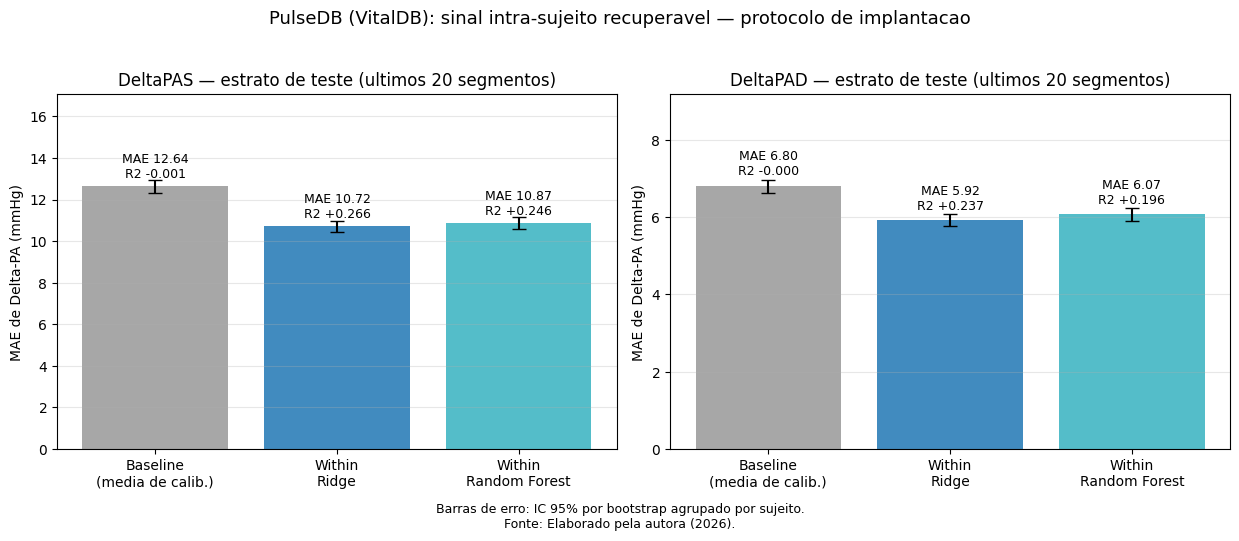

[figura] NB13_resultado_principal.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, alvo in zip(axes, ["PAS", "PAD"]):
    sub = res_principal[res_principal.alvo == alvo]
    nomes = ["Baseline\n(media de calib.)", "Within\nRidge", "Within\nRandom Forest"]
    cores = ["#9e9e9e", "#2c7fb8", "#41b6c4"]
    y = sub.MAE.values
    err = np.vstack([y - sub.MAE_lo.values, sub.MAE_hi.values - y])
    ax.bar(nomes, y, yerr=err, capsize=5, color=cores, alpha=.9)
    for i, (v, r2) in enumerate(zip(y, sub.R2.values)):
        ax.text(i, v + err[1][i] + .12, f"MAE {v:.2f}\nR2 {r2:+.3f}",
                ha="center", fontsize=9)
    ax.set_ylabel("MAE de Delta-PA (mmHg)")
    ax.set_title(f"Delta{alvo} — estrato de teste (ultimos {N_CAL} segmentos)")
    ax.set_ylim(0, max(y) * 1.35); ax.grid(alpha=.3, axis="y")

fig.suptitle("PulseDB (VitalDB): sinal intra-sujeito recuperavel — protocolo de implantacao",
             y=1.03, fontsize=13)
fig.text(0.5, -0.05, "Barras de erro: IC 95% por bootstrap agrupado por sujeito.\n"
                     "Fonte: Elaborado pela autora (2026).", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(PASTA_FIGS / "NB13_resultado_principal.png", dpi=300, bbox_inches="tight")
plt.show()
print("[figura] NB13_resultado_principal.png")

## 4. Análise secundária (within global) — com o vazamento declarado

Uma variante comum na literatura centra features e alvo pela média de **todos** os segmentos do
sujeito e valida com partição por sujeito. Ela produz um R² mais alto — mas contém um vazamento
sutil: **a média usada para centrar o alvo inclui os segmentos de teste**. Na prática isso
equivale a conhecer de antemão a PA média do período que se quer prever.

Reportamos essa variante **apenas para quantificar o viés**. O número a citar é o da Seção 3.

In [10]:
g_todos = seg.groupby("subject")
X_global = seg[FEATS].values - g_todos[FEATS].transform("mean").values   # <- usa TODOS os segmentos
grupos_global = seg.subject.values
sujeitos_global = np.unique(grupos_global)

linhas_sec = []
for alvo, col in [("PAS", "bp_sys_mean"), ("PAD", "bp_dia_mean")]:
    y = (seg[col] - g_todos[col].transform("mean")).values     # <- alvo tambem centrado com teste
    p = np.zeros(len(y))
    for i_tr, i_te in KFold(N_SPLITS, shuffle=True, random_state=SEED).split(sujeitos_global):
        m_tr = np.isin(grupos_global, sujeitos_global[i_tr])
        m_te = np.isin(grupos_global, sujeitos_global[i_te])
        sc = StandardScaler().fit(X_global[m_tr])
        p[m_te] = RidgeCV(alphas=ALPHAS).fit(
            sc.transform(X_global[m_tr]), y[m_tr]).predict(sc.transform(X_global[m_te]))
    linhas_sec.append({"alvo": alvo, "modelo": "Within global (COM vazamento de media)",
                       **metricas(y, p)})
    linhas_sec.append({"alvo": alvo, "modelo": "Baseline (media global do sujeito)",
                       **metricas(y, np.zeros(len(y)))})
    globals()[f"pred_global_{alvo}"] = p
    globals()[f"y_global_{alvo}"] = y

res_sec = pd.DataFrame(linhas_sec)
print(res_sec.to_string(index=False, float_format=lambda v: f"{v:9.4f}"))

print("\nQUANTIFICACAO DO VIES (R2 inflado pelo vazamento de media):")
for alvo in ["PAS", "PAD"]:
    r_sec = res_sec[(res_sec.alvo == alvo) & res_sec.modelo.str.contains("vazamento")].R2.iloc[0]
    r_pri = res_principal[(res_principal.alvo == alvo) &
                          (res_principal.modelo == "Within LINEAR (Ridge)")].R2.iloc[0]
    print(f"  {alvo}: within global = {r_sec:.4f} | implantacao = {r_pri:.4f} "
          f"| INFLACAO = +{r_sec - r_pri:.4f} ({100*(r_sec-r_pri)/r_pri:+.1f}%)")

res_sec.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}analise_secundaria.csv", index=False)
print(f"\n[salvo] {PREFIXO}analise_secundaria.csv")

alvo                                 modelo       MAE      RMSE        R2        ME        SD     n
 PAS Within global (COM vazamento de media)    8.8460   11.8559    0.3119    0.0000   11.8561 51720
 PAS     Baseline (media global do sujeito)   10.7544   14.2925    0.0000    0.0000   14.2927 51720
 PAD Within global (COM vazamento de media)    4.8371    6.6047    0.2911    0.0000    6.6047 51720
 PAD     Baseline (media global do sujeito)    5.7929    7.8441    0.0000    0.0000    7.8442 51720

QUANTIFICACAO DO VIES (R2 inflado pelo vazamento de media):
  PAS: within global = 0.3119 | implantacao = 0.2663 | INFLACAO = +0.0456 (+17.1%)
  PAD: within global = 0.2911 | implantacao = 0.2366 | INFLACAO = +0.0544 (+23.0%)

[salvo] _nb13_analise_secundaria.csv


## 5. Ablações — de onde vem o sinal?

Duas perguntas que um revisor faz de imediato:

1. **É apenas frequência cardíaca?** A FC muda com o estado hemodinâmico e é trivialmente
   obtida do PPG; se o sinal for só FC, não há contribuição da morfologia.
2. **É artefato de ganho do sensor?** As features de escala (`amplitude`, `peak_value`,
   `valley_value`, `variance`, `std`, `hjorth_activity`) dependem da amplitude bruta do PPG,
   sensível a pressão de contato e perfusão. A **Versão C** do projeto (35 features) já as
   exclui — usamos a mesma lista.

In [11]:
# Lista oficial da Versao C (35 features, sem PTT e sem features de escala)
with open(ARQ_CONFIG, "r", encoding="utf-8") as f:
    FEATURES_VC = set(json.load(f)["C"]["features"])

FC_FEATS    = ["heart_rate_bpm", "cardiac_period_s"]
TEMPO       = ["systolic_upstroke_time_s", "diastolic_time_s", "sut_dt_ratio"]
LARGURAS    = [f for f in FEATS if f.startswith("w")]
AMPLITUDE   = ["amplitude", "peak_value", "valley_value", "crest_factor"]
ESTATISTICA = ["variance", "std", "skewness", "kurtosis", "auc",
               "hjorth_activity", "hjorth_mobility", "hjorth_complexity"]
SEM_ESCALA  = [f for f in FEATS if f in FEATURES_VC]        # 35 (Versao C)
COM_ESCALA  = [f for f in FEATS if f not in FEATURES_VC]    # 6
REDUZIDO15  = [f for f in FEATS if not f.startswith("w") and f not in FC_FEATS]

# Redundancias EXATAS do extrator (verificadas na Secao 8.5):
#   hjorth_activity == variance          (a atividade de Hjorth E a variancia do sinal)
#   amplitude       == peak_value - valley_value
# Removemos uma de cada par para obter uma base de posto cheio.
DUPLICADAS = ["hjorth_activity", "peak_value"]
REDUZIDO39 = [f for f in FEATS if f not in DUPLICADAS]      # so remove as redundancias exatas
REDUZIDO13 = [f for f in REDUZIDO15 if f not in DUPLICADAS]

CONJUNTOS = [
    ("Todas as 41 features",            FEATS),
    ("SO frequencia cardiaca",          FC_FEATS),
    ("SEM frequencia cardiaca",         [f for f in FEATS if f not in FC_FEATS]),
    ("SO larguras de pulso",            LARGURAS),
    ("SO tempos sistole/diastole",      TEMPO),
    ("SO amplitude",                    AMPLITUDE),
    ("SO estatisticas/Hjorth",          ESTATISTICA),
    ("SEM escala — Versao C",           SEM_ESCALA),
    ("SO as 6 de escala",               COM_ESCALA),
    ("SEM redundancias exatas",         REDUZIDO39),
    ("REDUZIDO (sem larguras nem FC)",  REDUZIDO15),
    ("REDUZIDO SEM DUPLICATAS",         REDUZIDO13),
]
print(f"Versao C: {len(SEM_ESCALA)} features | de escala: {COM_ESCALA}")
print(f"Reduzido: {len(REDUZIDO15)} features | sem duplicatas: {len(REDUZIDO13)}\n")

linhas_abl = []
for nome, fs in CONJUNTOS:
    d = monta_within(feats=fs)
    linha = {"conjunto": nome, "n_features": len(fs)}
    for alvo in ["PAS", "PAD"]:
        r = valida_por_sujeito(d, alvo, modelo="ridge")
        linha[f"R2_{alvo}"]  = r2_score(r["y"], r["pred"])
        linha[f"MAE_{alvo}"] = mean_absolute_error(r["y"], r["pred"])
    linhas_abl.append(linha)
    print(f"  {nome:<34s} n={len(fs):>2d}  R2_PAS={linha['R2_PAS']:+.4f}  "
          f"R2_PAD={linha['R2_PAD']:+.4f}")

res_abl = pd.DataFrame(linhas_abl)
res_abl.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}ablacoes.csv", index=False)
print(f"\n[salvo] {PREFIXO}ablacoes.csv")

Versao C: 35 features | de escala: ['amplitude', 'peak_value', 'valley_value', 'variance', 'std', 'hjorth_activity']
Reduzido: 15 features | sem duplicatas: 13



  Todas as 41 features               n=41  R2_PAS=+0.2663  R2_PAD=+0.2366


  SO frequencia cardiaca             n= 2  R2_PAS=+0.0088  R2_PAD=+0.0304


  SEM frequencia cardiaca            n=39  R2_PAS=+0.2327  R2_PAD=+0.2066


  SO larguras de pulso               n=24  R2_PAS=+0.1325  R2_PAD=+0.0969


  SO tempos sistole/diastole         n= 3  R2_PAS=+0.0225  R2_PAD=+0.0520


... (3 outputs left out)

  SO as 6 de escala                  n= 6  R2_PAS=+0.2032  R2_PAD=+0.1655


  SEM redundancias exatas            n=39  R2_PAS=+0.2663  R2_PAD=+0.2367


  REDUZIDO (sem larguras nem FC)     n=15  R2_PAS=+0.2356  R2_PAD=+0.2090


  REDUZIDO SEM DUPLICATAS            n=13  R2_PAS=+0.2356  R2_PAD=+0.2090

[salvo] _nb13_ablacoes.csv


### Figura 3 — Contribuição de cada grupo de features

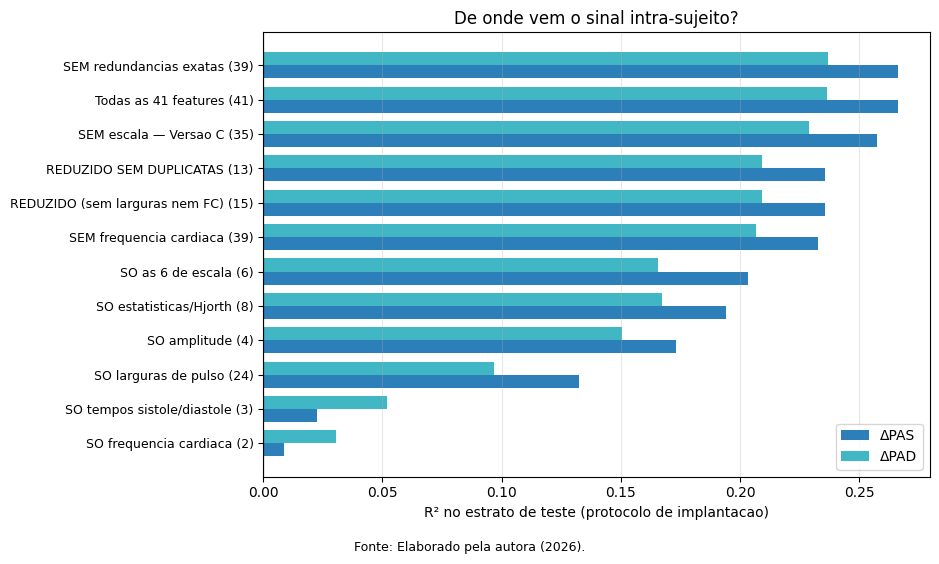

[figura] NB13_ablacoes.png


In [12]:
fig, ax = plt.subplots(figsize=(9.5, 5.4))
o = res_abl.sort_values("R2_PAS")
yy = np.arange(len(o))
ax.barh(yy - .19, o.R2_PAS, height=.38, color="#2c7fb8", label="ΔPAS")
ax.barh(yy + .19, o.R2_PAD, height=.38, color="#41b6c4", label="ΔPAD")
ax.set_yticks(yy); ax.set_yticklabels([f"{c} ({n})" for c, n in zip(o.conjunto, o.n_features)],
                                      fontsize=9)
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("R² no estrato de teste (protocolo de implantacao)")
ax.set_title("De onde vem o sinal intra-sujeito?")
ax.legend(); ax.grid(alpha=.3, axis="x")
fig.text(0.5, -0.03, "Fonte: Elaborado pela autora (2026).", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(PASTA_FIGS / "NB13_ablacoes.png", dpi=300, bbox_inches="tight")
plt.show()
print("[figura] NB13_ablacoes.png")

## 6. Contraste direto com o PTT-PPG

O mesmo pipeline — mesmas 41 features, mesma transformação within, validação deixando um
sujeito de fora (LOSO, pois são só 22 sujeitos) — aplicado ao PTT-PPG. Aqui a unidade
intra-sujeito é a **condição** (sit/walk/run), com apenas 2-3 valores por sujeito.

**Atualizado para a base corrigida (v3).** O contraste primário passa a usar
`_features_v3_clean.csv` — a re-extração vale-a-vale do PTT-PPG feita pelo **Notebook 15**, que é
a *mesma* correção de segmentação que o Notebook 14 aplicou ao PulseDB. Assim os dois lados do
contraste usam extração idêntica. A célula abaixo roda as duas extrações lado a lado.

**A oscilação do R² é ela mesma informativa.** Da extração antiga (v2, 57 unidades) para a
corrigida (v3, 66 unidades), o R² do ΔPAS vai de −7,07 para −1,72 e o do ΔPAD de −9,00 para
−24,25 — números que ora melhoram, ora pioram, sem padrão. Isso **não** é um efeito a
interpretar: com 57 a 66 unidades sujeito×condição contra **41 preditores**, o modelo está
fortemente **superparametrizado**. Nesse regime o R² de teste mede *o quanto o overfitting vai
mal em cada configuração*, não capacidade preditiva — daí o salto errático quando a base muda.
Contraste com o PulseDB sob a **mesma** correção, onde o R² é estável (0,2783 → 0,2663): lá
existe sinal intra-sujeito ancorando o resultado; aqui não há variância intra-condição no rótulo
(uma única leitura de manguito por registro) para modelo algum regredir, e o que sobra medindo é
o comportamento do overfitting.


In [13]:
def _contraste_loso(seg_df, cols):
    """Protocolo within/LOSO da Secao 6 sobre um ptt_seg dado. Devolve linhas de metrica.

    Identico ao contraste original: centraliza features e rotulo por sujeito, Ridge com
    padronizacao no treino, deixando um sujeito inteiro de fora por vez.
    """
    g = seg_df.groupby("subject")
    X = seg_df[cols].values - g[cols].transform("mean").values
    grupos = seg_df.subject.values
    linhas = []
    for alvo, col in [("PAS", "bp_sys_mean"), ("PAD", "bp_dia_mean")]:
        y = (seg_df[col] - g[col].transform("mean")).values
        p = np.zeros(len(y))
        for i_tr, i_te in LeaveOneGroupOut().split(X, y, grupos):
            sc = StandardScaler().fit(X[i_tr])
            p[i_te] = RidgeCV(alphas=ALPHAS).fit(
                sc.transform(X[i_tr]), y[i_tr]).predict(sc.transform(X[i_te]))
        linhas.append({"alvo": alvo, "modelo": "Within Ridge (LOSO)", **metricas(y, p)})
        linhas.append({"alvo": alvo, "modelo": "Baseline (media do sujeito)",
                       **metricas(y, np.zeros(len(y)))})
    return pd.DataFrame(linhas)


# --- v3 (extracao corrigida vale-a-vale, NB15) = base PRIMARIA do contraste ---
ptt_v3 = pd.read_csv(ARQ_PTTPPG_V3,
                     usecols=COLS_PTT + ["subject", "condition", "bp_sys_mean", "bp_dia_mean"])
ptt_v3 = ptt_v3.replace([np.inf, -np.inf], np.nan).dropna(subset=COLS_PTT)
ptt_seg_v3 = ptt_v3.groupby(["subject", "condition"], as_index=False).agg(
    {**{f: "mean" for f in COLS_PTT}, "bp_sys_mean": "first", "bp_dia_mean": "first"})

res_ptt_v3 = _contraste_loso(ptt_seg_v3, COLS_PTT).assign(base="PTT-PPG (v3)")
res_ptt_v2 = _contraste_loso(ptt_seg,    COLS_PTT).assign(base="PTT-PPG (v2)")  # ptt_seg = v2 (Secao 2)
res_ptt = res_ptt_v3   # <<< base primaria usada no restante do notebook (conferencia da Secao 10)

print(f"PTT-PPG v3 (corrigido, NB15): {len(ptt_seg_v3)} unidades (sujeito x condicao) | "
      f"{ptt_seg_v3.subject.nunique()} sujeitos")
print(f"PTT-PPG v2 (antigo):          {len(ptt_seg)} unidades (sujeito x condicao)\n")
print(res_ptt_v3[["base", "alvo", "modelo", "MAE", "RMSE", "R2", "n"]].to_string(
    index=False, float_format=lambda v: f"{v:9.4f}"))

r2_pulse_pas = float(res_principal[(res_principal.alvo == "PAS") &
                     (res_principal.modelo == "Within LINEAR (Ridge)")].R2.iloc[0])
R2_PULSEDB_ANTIGO_PAS = 0.2783   # PulseDB pico-a-pico (documentado na Secao 10/11)

print("\nCONTRASTE within Ridge — v2 (pico-a-pico) vs v3 (vale-a-vale) vs PulseDB:")
for alvo in ["PAS", "PAD"]:
    a2 = res_ptt_v2[(res_ptt_v2.alvo == alvo) & res_ptt_v2.modelo.str.contains("Within")].R2.iloc[0]
    a3 = res_ptt_v3[(res_ptt_v3.alvo == alvo) & res_ptt_v3.modelo.str.contains("Within")].R2.iloc[0]
    b  = float(res_principal[(res_principal.alvo == alvo) &
               (res_principal.modelo == "Within LINEAR (Ridge)")].R2.iloc[0])
    print(f"  {alvo}: PTT-PPG v2 R2 = {a2:+8.4f} | v3 R2 = {a3:+8.4f} | PulseDB v3 R2 = {b:+.4f}")

n_un, n_pred = len(ptt_seg_v3), len(COLS_PTT)
print(f"\n=> R2 fortemente NEGATIVO no PTT-PPG em AMBAS as extracoes (v2 e v3): o modelo e MUITO")
print(f"   pior que repetir a media do sujeito. A oscilacao entre as extracoes e ela mesma")
print(f"   informativa: com {n_un} unidades sujeito x condicao contra {n_pred} preditores, o modelo")
print(f"   esta fortemente SUPERPARAMETRIZADO. O R2 de teste mede o quanto o overfitting vai mal")
print(f"   em cada configuracao, NAO capacidade preditiva. Contraste com a estabilidade do PulseDB")
print(f"   sob a MESMA correcao ({R2_PULSEDB_ANTIGO_PAS:.4f} antigo -> {r2_pulse_pas:.4f} corrigido,")
print(f"   R2 PAS): la existe sinal ancorando o resultado; aqui nao ha variancia intra-condicao no")
print(f"   rotulo para regredir, e o que sobra medindo e o comportamento do overfitting.")

res_ptt_v3.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}contraste_pttppg.csv", index=False)
res_ptt_v2.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}contraste_pttppg_v2.csv", index=False)
print(f"\n[salvo] {PREFIXO}contraste_pttppg.csv (v3) e {PREFIXO}contraste_pttppg_v2.csv")


PTT-PPG v3 (corrigido, NB15): 66 unidades (sujeito x condicao) | 22 sujeitos
PTT-PPG v2 (antigo):          57 unidades (sujeito x condicao)

        base alvo                      modelo       MAE      RMSE        R2  n
PTT-PPG (v3)  PAS         Within Ridge (LOSO)    3.4857    4.3712   -1.7198 66
PTT-PPG (v3)  PAS Baseline (media do sujeito)    2.0303    2.6505   -0.0000 66
PTT-PPG (v3)  PAD         Within Ridge (LOSO)    4.8283   11.6759  -24.2505 66
PTT-PPG (v3)  PAD Baseline (media do sujeito)    1.7020    2.3236    0.0000 66

CONTRASTE within Ridge — v2 (pico-a-pico) vs v3 (vale-a-vale) vs PulseDB:
  PAS: PTT-PPG v2 R2 =  -7.0710 | v3 R2 =  -1.7198 | PulseDB v3 R2 = +0.2663
  PAD: PTT-PPG v2 R2 =  -9.0006 | v3 R2 = -24.2505 | PulseDB v3 R2 = +0.2366

=> R2 fortemente NEGATIVO no PTT-PPG em AMBAS as extracoes (v2 e v3): o modelo e MUITO
   pior que repetir a media do sujeito. A oscilacao entre as extracoes e ela mesma
   informativa: com 66 unidades sujeito x condicao contra 41 pre

## 7. Avaliação AAMI / ISO 81060-2

O padrão exige **|ME| ≤ 5 mmHg** e **SD do erro ≤ 8 mmHg**. Aplicamos ao erro do protocolo de
implantação. Como a predição final é `média de calibração + ΔPA predito`, o erro do ΔPA **é** o
erro da PA absoluta — as duas avaliações coincidem.

In [14]:
def classificar_aami(me, sd):
    """Padrao AAMI/ISO 81060-2: passa se |ME| <= 5 e SD <= 8 mmHg."""
    return "PASSA" if (abs(me) <= 5 and sd <= 8) else "FALHA"

linhas_aami = []
for alvo in ["PAS", "PAD"]:
    yte = dados_impl["yte"][alvo]
    for nome, p in [("Baseline (media de calibracao)", np.zeros(len(yte))),
                    ("Within Ridge", resultados_impl[(alvo, "ridge")]["pred"]),
                    ("Within Random Forest", resultados_impl[(alvo, "rf")]["pred"])]:
        m = metricas(yte, p)
        linhas_aami.append({"alvo": alvo, "modelo": nome, "ME": m["ME"], "SD": m["SD"],
                            "MAE": m["MAE"], "RMSE": m["RMSE"],
                            "AAMI": classificar_aami(m["ME"], m["SD"])})

res_aami = pd.DataFrame(linhas_aami)
print("Referencia AAMI/ISO 81060-2: |ME| <= 5 mmHg e SD <= 8 mmHg\n")
print(res_aami.to_string(index=False, float_format=lambda v: f"{v:8.3f}"))

# Leitura gerada a partir da PROPRIA tabela, para nao divergir dela
def _linha(alvo, modelo):
    return res_aami[(res_aami.alvo == alvo) & (res_aami.modelo.str.contains(modelo))].iloc[0]

print("\nLEITURA (derivada da tabela acima):")
for alvo in ["PAS", "PAD"]:
    b, r = _linha(alvo, "Baseline"), _linha(alvo, "Ridge")
    if b.AAMI == "FALHA" and r.AAMI == "PASSA":
        print(f"  {alvo}: o modelo CRUZA um limiar que o baseline nao cruza "
              f"(SD {b.SD:.3f} -> {r.SD:.3f}; limite 8 mmHg). O ganho e clinicamente relevante:")
        print(f"       a calibracao sozinha REPROVA no AAMI e o modelo APROVA.")
    elif b.AAMI == "FALHA" and r.AAMI == "FALHA":
        print(f"  {alvo}: modelo melhora o SD ({b.SD:.3f} -> {r.SD:.3f}) mas AMBOS reprovam "
              f"— segue longe do limite de 8 mmHg.")
    elif b.AAMI == "PASSA" and r.AAMI == "PASSA":
        print(f"  {alvo}: ambos passam (baseline SD {b.SD:.3f}); o merito do modelo "
              f"e menor do que a classificacao sugere.")
    else:
        print(f"  {alvo}: baseline {b.AAMI} / modelo {r.AAMI} (SD {b.SD:.3f} -> {r.SD:.3f}).")

res_aami.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}avaliacao_aami.csv", index=False)
print(f"\n[salvo] {PREFIXO}avaliacao_aami.csv")

Referencia AAMI/ISO 81060-2: |ME| <= 5 mmHg e SD <= 8 mmHg

alvo                         modelo       ME       SD      MAE     RMSE  AAMI
 PAS Baseline (media de calibracao)    0.447   16.511   12.638   16.517 FALHA
 PAS                   Within Ridge   -0.771   14.122   10.718   14.143 FALHA
 PAS           Within Random Forest   -0.951   14.310   10.875   14.341 FALHA
 PAD Baseline (media de calibracao)    0.174    8.983    6.796    8.985 FALHA
 PAD                   Within Ridge   -0.585    7.827    5.920    7.849 PASSA
 PAD           Within Random Forest   -0.728    8.024    6.068    8.057 FALHA

LEITURA (derivada da tabela acima):
  PAS: modelo melhora o SD (16.511 -> 14.122) mas AMBOS reprovam — segue longe do limite de 8 mmHg.
  PAD: o modelo CRUZA um limiar que o baseline nao cruza (SD 8.983 -> 7.827; limite 8 mmHg). O ganho e clinicamente relevante:
       a calibracao sozinha REPROVA no AAMI e o modelo APROVA.

[salvo] _nb13_avaliacao_aami.csv


## 8. Verificações de robustez

Cinco controles contra as objeções que um revisor levantaria.

### 8.1 Teste de permutação (controle negativo)

Embaralhamos ΔPA **dentro de cada sujeito** — preservando estrutura de sujeito, split e
centralização — e re-treinamos. Se houvesse vazamento estrutural, o R² permutado não
colapsaria para zero. São **1.000 permutações**, o que permite p < 0,001.

Para viabilizar 1.000 re-treinos, exploramos que a matriz de features é **fixa** entre
permutações: pré-calculamos a SVD de cada fold e resolvemos o Ridge em forma fechada. O α de
cada fold é o selecionado pelo `RidgeCV` nos dados reais (sob a nula, a regularização é
irrelevante). Conferimos que o R² real com α fixo reproduz o do `RidgeCV`.

In [15]:
def prepara_svd(dados, alvo):
    """Pre-calcula, por fold, o scaler, a SVD do treino e o alpha do RidgeCV real."""
    Xtr, Xte = dados["Xtr"], dados["Xte"]
    gtr, gte = dados["gtr"], dados["gte"]
    ytr = dados["ytr"][alvo]
    sujeitos = np.unique(gtr)
    folds = []
    for i_tr, i_te in KFold(N_SPLITS, shuffle=True, random_state=SEED).split(sujeitos):
        m_tr = np.isin(gtr, sujeitos[i_tr]); m_te = np.isin(gte, sujeitos[i_te])
        sc = StandardScaler().fit(Xtr[m_tr])
        Xs = sc.transform(Xtr[m_tr])
        alpha = RidgeCV(alphas=ALPHAS).fit(Xs, ytr[m_tr]).alpha_
        U, S, Vt = np.linalg.svd(Xs, full_matrices=False)
        folds.append({"m_tr": m_tr, "m_te": m_te, "U": U, "S": S, "Vt": Vt,
                      "alpha": alpha, "Xte_s": sc.transform(Xte[m_te])})
    return folds


def ridge_svd(folds, ytr, yte_len):
    """Ridge em forma fechada via SVD (equivalente a Ridge(alpha) com intercepto)."""
    pred = np.zeros(yte_len)
    for f in folds:
        yc = ytr[f["m_tr"]]
        media = yc.mean()
        d = f["S"] / (f["S"] ** 2 + f["alpha"])
        w = f["Vt"].T @ (d * (f["U"].T @ (yc - media)))
        pred[f["m_te"]] = f["Xte_s"] @ w + media
    return pred


linhas_perm, nulas = [], {}
for alvo in ["PAS", "PAD"]:
    folds = prepara_svd(dados_impl, alvo)
    ytr, yte = dados_impl["ytr"][alvo], dados_impl["yte"][alvo]
    gtr, gte = dados_impl["gtr"], dados_impl["gte"]

    # conferencia: forma fechada reproduz o RidgeCV?
    r2_svd = r2_score(yte, ridge_svd(folds, ytr, len(yte)))
    r2_ref = r2_score(yte, resultados_impl[(alvo, "ridge")]["pred"])
    print(f"{alvo}: R2 RidgeCV={r2_ref:.4f} | R2 forma fechada={r2_svd:.4f} "
          f"| dif={abs(r2_svd-r2_ref):.2e}")

    idx_tr = [np.where(gtr == s)[0] for s in np.unique(gtr)]
    idx_te = [np.where(gte == s)[0] for s in np.unique(gte)]
    rng = np.random.default_rng(2024)
    nula = np.empty(N_PERM)
    for i in range(N_PERM):
        ytr_p, yte_p = ytr.copy(), yte.copy()
        for ii in idx_tr:                       # embaralha DENTRO de cada sujeito
            ytr_p[ii] = rng.permutation(ytr_p[ii])
        for ii in idx_te:
            yte_p[ii] = rng.permutation(yte_p[ii])
        nula[i] = r2_score(yte_p, ridge_svd(folds, ytr_p, len(yte_p)))
    nulas[alvo] = nula

    p_emp = (np.sum(nula >= r2_ref) + 1) / (N_PERM + 1)
    z = (r2_ref - nula.mean()) / nula.std(ddof=1)
    linhas_perm.append({"alvo": alvo, "R2_real": r2_ref, "nula_media": nula.mean(),
                        "nula_sd": nula.std(ddof=1), "nula_min": nula.min(),
                        "nula_max": nula.max(), "nula_p95": np.percentile(nula, 95),
                        "z": z, "p_empirico": p_emp, "n_perm": N_PERM})
    print(f"  nula: media={nula.mean():+.5f} sd={nula.std(ddof=1):.5f} "
          f"max={nula.max():+.5f} | R2 real={r2_ref:+.4f} -> z={z:+.1f} | p={p_emp:.4f}\n")

res_perm = pd.DataFrame(linhas_perm)
res_perm.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}permutacao.csv", index=False)
pd.DataFrame(nulas).to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}distribuicao_nula.csv", index=False)
print(f"[salvo] {PREFIXO}permutacao.csv e {PREFIXO}distribuicao_nula.csv")

PAS: R2 RidgeCV=0.2663 | R2 forma fechada=0.2663 | dif=2.81e-09


  nula: media=-0.00239 sd=0.00407 max=+0.00854 | R2 real=+0.2663 -> z=+66.0 | p=0.0010



PAD: R2 RidgeCV=0.2366 | R2 forma fechada=0.2366 | dif=1.34e-09


  nula: media=-0.00201 sd=0.00378 max=+0.00927 | R2 real=+0.2366 -> z=+63.1 | p=0.0010

[salvo] _nb13_permutacao.csv e _nb13_distribuicao_nula.csv


#### Figura 4 — Distribuição nula do teste de permutação

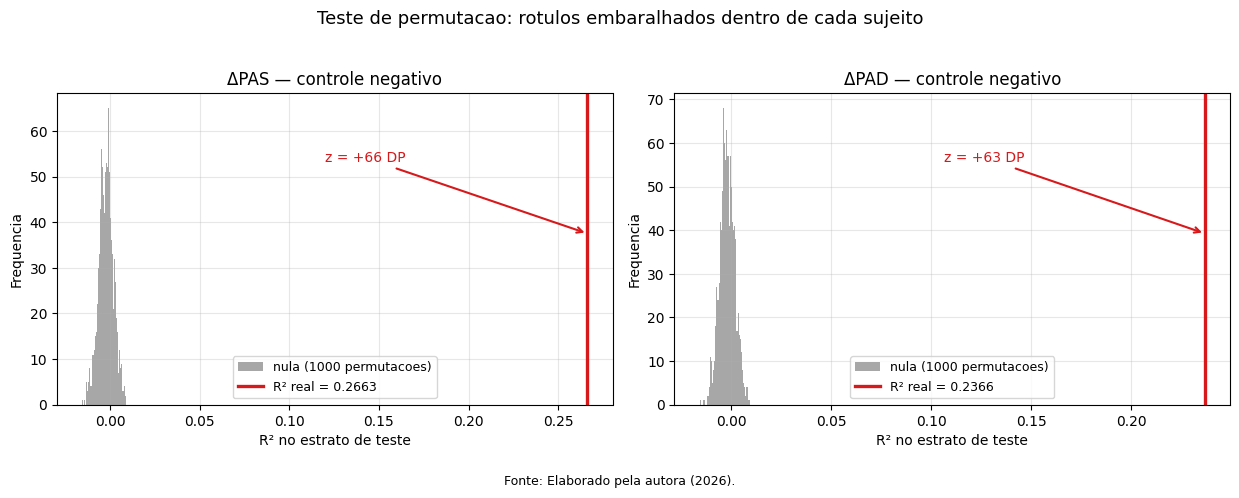

[figura] NB13_permutacao.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for ax, alvo in zip(axes, ["PAS", "PAD"]):
    nula = nulas[alvo]
    real = res_perm[res_perm.alvo == alvo].R2_real.iloc[0]
    z = res_perm[res_perm.alvo == alvo].z.iloc[0]
    ax.hist(nula, bins=45, color="#9e9e9e", alpha=.9, label=f"nula ({N_PERM} permutacoes)")
    ax.axvline(real, color="#d7191c", lw=2.4, label=f"R² real = {real:.4f}")
    ax.annotate(f"z = {z:+.0f} DP", xy=(real, ax.get_ylim()[1]*.55),
                xytext=(real*.45, ax.get_ylim()[1]*.78), fontsize=10, color="#d7191c",
                arrowprops=dict(arrowstyle="->", color="#d7191c", lw=1.5))
    ax.set_xlabel("R² no estrato de teste"); ax.set_ylabel("Frequencia")
    ax.set_title(f"Δ{alvo} — controle negativo"); ax.legend(fontsize=9); ax.grid(alpha=.3)
fig.suptitle("Teste de permutacao: rotulos embaralhados dentro de cada sujeito",
             y=1.03, fontsize=13)
fig.text(0.5, -0.05, "Fonte: Elaborado pela autora (2026).", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(PASTA_FIGS / "NB13_permutacao.png", dpi=300, bbox_inches="tight")
plt.show()
print("[figura] NB13_permutacao.png")

### 8.2 Auditoria de vazamento na centralização

Prova empírica: destruímos **todos** os rótulos e features do bloco de teste e verificamos que
nenhuma constante de treino muda. Contraprova: corromper a *calibração* deve alterá-las
(senão o teste não teria poder de detecção).

In [17]:
def constantes_treino(df):
    """Reproduz exatamente as constantes que monta_within() calcula."""
    cal = df[df.ordem < N_CAL]
    gc = cal.groupby("subject")
    return {
        "media_features": cal.groupby("subject")[FEATS].mean().values,
        "media_PAS":      cal.groupby("subject")["bp_sys_mean"].mean().values,
        "media_PAD":      cal.groupby("subject")["bp_dia_mean"].mean().values,
        "X_treino":       cal[FEATS].values - gc[FEATS].transform("mean").values,
        "y_treino":       (cal.bp_sys_mean - gc.bp_sys_mean.transform("mean")).values,
    }

# Usamos uma copia em float64 nas DUAS versoes: comparar float32 com float64
# produziria diferenca de arredondamento e mascararia o resultado do teste.
seg64 = seg.copy()
seg64[FEATS] = seg64[FEATS].astype("float64")
base_const = constantes_treino(seg64)

# --- corrompe TUDO no bloco de teste ---
rng = np.random.default_rng(0)
corrompido = seg64.copy()
mask_teste = corrompido.ordem >= N_CAL
corrompido.loc[mask_teste, "bp_sys_mean"] = rng.normal(999, 50, int(mask_teste.sum()))
corrompido.loc[mask_teste, "bp_dia_mean"] = rng.normal(-999, 50, int(mask_teste.sum()))
corrompido.loc[mask_teste, FEATS] = rng.normal(1e6, 1e5, (int(mask_teste.sum()), len(FEATS)))
novo_const = constantes_treino(corrompido)

linhas_vaz, tudo_ok = [], True
print("Apos destruir TODOS os rotulos e features do bloco de TESTE:")
for k in base_const:
    identico = np.array_equal(np.asarray(base_const[k], float), np.asarray(novo_const[k], float))
    tudo_ok &= identico
    linhas_vaz.append({"constante": k, "identica_bitwise": bool(identico)})
    print(f"  {k:<16s} identica (bitwise)? {'SIM' if identico else 'NAO'}")

# --- contraprova: corromper a CALIBRACAO deve mudar ---
corr2 = seg64.copy()
mask_cal = corr2.ordem < N_CAL
corr2.loc[mask_cal, "bp_sys_mean"] = rng.normal(999, 50, int(mask_cal.sum()))
mudou = not np.array_equal(base_const["media_PAS"], constantes_treino(corr2)["media_PAS"])
print(f"\n  Contraprova (corromper a CALIBRACAO altera media_PAS)? "
      f"{'SIM — teste tem poder' if mudou else 'NAO — teste invalido'}")
print(f"\n  VEREDITO: {'nenhuma constante de treino depende do bloco de teste' if (tudo_ok and mudou) else 'ATENCAO'}")

pd.DataFrame(linhas_vaz).assign(contraprova_detecta=mudou).to_csv(
    PASTA_PULSEDB_FEAT / f"{PREFIXO}auditoria_vazamento.csv", index=False)
print(f"[salvo] {PREFIXO}auditoria_vazamento.csv")

Apos destruir TODOS os rotulos e features do bloco de TESTE:
  media_features   identica (bitwise)? SIM
  media_PAS        identica (bitwise)? SIM
  media_PAD        identica (bitwise)? SIM
  X_treino         identica (bitwise)? SIM
  y_treino         identica (bitwise)? SIM

  Contraprova (corromper a CALIBRACAO altera media_PAS)? SIM — teste tem poder

  VEREDITO: nenhuma constante de treino depende do bloco de teste
[salvo] _nb13_auditoria_vazamento.csv


### 8.3 Split em blocos temporais com intervalo (gap)

Se o resultado dependesse de autocorrelação entre segmentos próximos, afastar calibração e
teste derrubaria o R². Testamos gaps de 0, 5 e 10 segmentos (com `n_cal = 15` fixo, para que
as variantes sejam comparáveis) e também a **ordem invertida**, que detectaria deriva temporal.

*Limitação a declarar:* a redistribuição do Kaggle **não preserva o instante de aquisição** dos
segmentos (a struct do `.mat` traz apenas `Age, BMI, DBP, Gender, Height, SBP, Signals,
Subject, Weight`). Cada segmento tem 10 s de sinal, mas o intervalo de relógio entre eles é
desconhecido — por isso o eixo é **ordinal**, não em minutos.

In [18]:
linhas_gap = []
for rotulo, n_cal, gap, inv in [("gap = 0 segmentos", 15, 0, False),
                                ("gap = 5 segmentos", 15, 5, False),
                                ("gap = 10 segmentos", 15, 10, False),
                                ("ordem INVERTIDA", 15, 0, True)]:
    d = monta_within(n_cal=n_cal, gap=gap, inverter=inv)
    linha = {"variante": rotulo, "n_teste": len(d["Xte"])}
    for alvo in ["PAS", "PAD"]:
        r = valida_por_sujeito(d, alvo, modelo="ridge")
        linha[f"R2_{alvo}"]  = r2_score(r["y"], r["pred"])
        linha[f"MAE_{alvo}"] = mean_absolute_error(r["y"], r["pred"])
        linha[f"MAEbase_{alvo}"] = mean_absolute_error(r["y"], np.zeros(len(r["y"])))
    linhas_gap.append(linha)
    print(f"  {rotulo:<22s} n={linha['n_teste']:>6d}  R2_PAS={linha['R2_PAS']:.4f}  "
          f"R2_PAD={linha['R2_PAD']:.4f}")

res_gap = pd.DataFrame(linhas_gap)
print("\n=> R2 praticamente constante ao longo do gap: nao ha inflacao por autocorrelacao.")
res_gap.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}split_blocos_gap.csv", index=False)
print(f"[salvo] {PREFIXO}split_blocos_gap.csv")

  gap = 0 segmentos      n= 32325  R2_PAS=0.2497  R2_PAD=0.2259


  gap = 5 segmentos      n= 25860  R2_PAS=0.2476  R2_PAD=0.2204


  gap = 10 segmentos     n= 19395  R2_PAS=0.2447  R2_PAD=0.2144


  ordem INVERTIDA        n= 32325  R2_PAS=0.2865  R2_PAD=0.2579

=> R2 praticamente constante ao longo do gap: nao ha inflacao por autocorrelacao.
[salvo] _nb13_split_blocos_gap.csv


In [19]:
# Desempenho em funcao da distancia (ordinal) ao bloco de calibracao
linhas_dist = []
for alvo in ["PAS", "PAD"]:
    r = resultados_impl[(alvo, "ridge")]
    dist = dados_impl["ordem_te"] - (N_CAL - 1)     # 1 = primeiro segmento apos a calibracao
    for lo, hi in [(1, 4), (5, 8), (9, 12), (13, 16), (17, 20)]:
        m = (dist >= lo) & (dist <= hi)
        if m.sum() < 50:
            continue
        mae = mean_absolute_error(r["y"][m], r["pred"][m])
        base = mean_absolute_error(r["y"][m], np.zeros(int(m.sum())))
        linhas_dist.append({"alvo": alvo, "faixa_segmentos": f"{lo}-{hi}", "n": int(m.sum()),
                            "R2": r2_score(r["y"][m], r["pred"][m]), "MAE": mae,
                            "MAE_baseline": base, "razao_MAE": mae / base})
    rho = st.spearmanr(dist, np.abs(r["y"] - r["pred"]))
    print(f"{alvo}: Spearman(distancia, |erro|) = {rho.statistic:+.4f}  p={rho.pvalue:.2e}")

res_dist = pd.DataFrame(linhas_dist)
print()
print(res_dist.to_string(index=False, float_format=lambda v: f"{v:8.4f}"))
print("\n=> o erro ABSOLUTO cresce com a distancia, mas o do baseline cresce junto:")
print("   a razao MAE/baseline fica estavel. A vantagem relativa do modelo nao expira.")
res_dist.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}distancia_calibracao.csv", index=False)
print(f"[salvo] {PREFIXO}distancia_calibracao.csv")

PAS: Spearman(distancia, |erro|) = +0.1268  p=3.56e-93
PAD: Spearman(distancia, |erro|) = +0.1363  p=1.71e-107

alvo faixa_segmentos    n       R2      MAE  MAE_baseline  razao_MAE
 PAS             1-4 5172   0.2838   9.0770       10.9113     0.8319
 PAS             5-8 5172   0.2567   9.9839       11.7567     0.8492
 PAS            9-12 5172   0.2378  10.4026       12.2136     0.8517
 PAS           13-16 5172   0.1851  11.2121       12.5998     0.8899
 PAS           17-20 5172   0.2904  12.9167       15.7106     0.8222
 PAD             1-4 5172   0.2745   4.9761        5.8648     0.8485
 PAD             5-8 5172   0.2387   5.3783        6.2028     0.8671
 PAD            9-12 5172   0.2218   5.8110        6.6595     0.8726
 PAD           13-16 5172   0.1621   6.3500        6.9744     0.9105
 PAD           17-20 5172   0.2602   7.0836        8.2765     0.8559

=> o erro ABSOLUTO cresce com a distancia, mas o do baseline cresce junto:
   a razao MAE/baseline fica estavel. A vantagem rela

### 8.4 Estabilidade por fold

R² e MAE de cada um dos 5 folds, e as 10 features de maior peso no Ridge em cada fold.

In [20]:
linhas_fold, coef_por_alvo = [], {}
for alvo in ["PAS", "PAD"]:
    r = resultados_impl[(alvo, "ridge")]
    print(f"--- Δ{alvo} (agregado R2={r2_score(r['y'], r['pred']):.4f}) ---")
    print(f"  {'fold':<6s}{'n_teste':>9s}{'sujeitos':>10s}{'R2':>9s}{'MAE':>9s}"
          f"{'MAE_base':>10s}{'alpha':>10s}")
    for k in range(1, N_SPLITS + 1):
        m = r["fold"] == k
        linha = {"alvo": alvo, "fold": k, "n_teste": int(m.sum()),
                 "n_sujeitos": int(len(np.unique(r["grupo"][m]))),
                 "R2": r2_score(r["y"][m], r["pred"][m]),
                 "MAE": mean_absolute_error(r["y"][m], r["pred"][m]),
                 "MAE_baseline": mean_absolute_error(r["y"][m], np.zeros(int(m.sum()))),
                 "alpha": r["alphas"][k-1]}
        linhas_fold.append(linha)
        print(f"  {k:<6d}{linha['n_teste']:>9d}{linha['n_sujeitos']:>10d}"
              f"{linha['R2']:>9.4f}{linha['MAE']:>9.4f}{linha['MAE_baseline']:>10.4f}"
              f"{linha['alpha']:>10.3f}")
    Coef = pd.DataFrame({f"fold{i+1}": c for i, c in enumerate(r["coefs"])})
    coef_por_alvo[alvo] = Coef
    top = Coef.abs().mean(axis=1).sort_values(ascending=False).head(10).index.tolist()
    print(f"\n  TOP-10 por |coef| medio: {', '.join(top)}")
    tau = np.mean([st.kendalltau(Coef.abs().rank(ascending=False)[f"fold{i}"],
                                 Coef.abs().rank(ascending=False)[f"fold{j}"]).statistic
                   for i in range(1, 6) for j in range(i+1, 6)])
    tops = [set(Coef[f"fold{i}"].abs().sort_values(ascending=False).head(10).index)
            for i in range(1, 6)]
    jac = np.mean([len(a & b)/len(a | b) for i, a in enumerate(tops) for b in tops[i+1:]])
    print(f"  Kendall tau medio entre folds = {tau:.4f} | Jaccard do TOP-10 = {jac:.4f}\n")

res_fold = pd.DataFrame(linhas_fold)
res_fold.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}estabilidade_folds.csv", index=False)
print(f"[salvo] {PREFIXO}estabilidade_folds.csv")

--- ΔPAS (agregado R2=0.2663) ---
  fold    n_teste  sujeitos       R2      MAE  MAE_base     alpha
  1          5180       259   0.2575  10.6638   12.6689     1.000
  2          5180       259   0.2256  10.3250   11.9266     1.000
  3          5180       259   0.2606  10.6535   12.4784     1.000
  4          5160       258   0.3338  10.7545   13.1421     1.000
  5          5160       258   0.2404  11.1976   12.9793     1.000

  TOP-10 por |coef| medio: std, skewness, heart_rate_bpm, hjorth_mobility, peak_value, amplitude, systolic_upstroke_time_s, sut_dt_ratio, hjorth_activity, variance
  Kendall tau medio entre folds = 0.8491 | Jaccard do TOP-10 = 0.9273

--- ΔPAD (agregado R2=0.2366) ---
  fold    n_teste  sujeitos       R2      MAE  MAE_base     alpha
  1          5180       259   0.2394   5.8866    6.7681     1.000
  2          5180       259   0.2687   5.8747    6.8747     1.000
  3          5180       259   0.2162   5.8066    6.6221     1.000
  4          5160       258   0.2427

### 8.5 Colinearidade — quanto dela era artefato do defeito de segmentação

Na versão anterior deste notebook, rodada sobre a extração pico-a-pico, pares como
`cardiac_period_s` × `w10_total` apresentavam correlação acima de 0,9999 e a matriz within tinha
posto 35 de 41. Aquilo **não era propriedade do sinal**: com o pico na borda do recorte,
`w*_sys` e `w*_dia` colapsavam em 0 ou na largura total, tornando dezenas de colunas
funcionalmente iguais.

Sobre a base corrigida (Notebook 14) as correlações caem para a faixa impressa abaixo, e restam
apenas **duas redundâncias — ambas por definição, não por defeito**:

- `hjorth_activity` ≡ `variance` — a *activity* de Hjorth **é** a variância do sinal;
- `amplitude` ≡ `peak_value − valley_value` — identidade algébrica.

São essas duas, e só essas, que mantêm a matriz de 41 colunas singular. Removê-las (Seção 9)
restaura o posto cheio.

In [21]:
W = pd.DataFrame(seg[FEATS].values - g_todos[FEATS].transform("mean").values, columns=FEATS)

PARES = [("cardiac_period_s", "w10_total"), ("cardiac_period_s", "w25_total"),
         ("w10_total", "w25_total"), ("w33_dia", "diastolic_time_s")]
print("Correlacoes no espaco within (precisao total):")
linhas_col = []
for a, b in PARES:
    c = W[a].corr(W[b])
    linhas_col.append({"feature_a": a, "feature_b": b, "correlacao": c})
    print(f"  corr({a}, {b}) = {c:.10f}")

Ws = StandardScaler().fit_transform(W.values)
sv = np.linalg.svd(Ws, compute_uv=False)
posto = int(np.linalg.matrix_rank(Ws, tol=1e-8))
print(f"\n  posto numerico = {posto} de {len(FEATS)} colunas")
print(f"  numero de condicao = {sv[0]/sv[-1]:.3e}")
print(f"  => {len(FEATS)-posto} direcoes linearmente dependentes: a matriz e singular.")

# Leitura da FC derivada da tabela de ablacoes (Secao 5), nao de valor fixo
_tudo = float(res_abl[res_abl.conjunto == "Todas as 41 features"].R2_PAS.iloc[0])
_semfc = float(res_abl[res_abl.conjunto == "SEM frequencia cardiaca"].R2_PAS.iloc[0])
_sofc = float(res_abl[res_abl.conjunto == "SO frequencia cardiaca"].R2_PAS.iloc[0])
print(f"\n  A FREQUENCIA CARDIACA E O MOTOR DO RESULTADO? (numeros da Secao 5)")
print(f"    R2 com todas as 41 features     : {_tudo:+.4f}")
print(f"    R2 sem frequencia cardiaca (39) : {_semfc:+.4f}  -> remove-la CUSTA {_tudo-_semfc:+.4f}")
print(f"    R2 so com frequencia cardiaca(2): {_sofc:+.4f}  -> sozinha preve praticamente nada")
print(f"  => a FC contribui EM COMBINACAO com a morfologia, mas isoladamente e quase inutil.")
print(f"     Logo o resultado NAO se reduz a deteccao de frequencia cardiaca — a conclusao")
print(f"     se mantem, agora pelo argumento do poder preditivo isolado ({_sofc:+.4f}),")
print(f"     nao pela ausencia de perda ao remove-la.")

# ─── Redundancias EXATAS entre features (nivel de ciclo, nao apenas correlacao alta) ───
amostra = pd.read_csv(ARQ_PULSEDB, usecols=FEATS, nrows=200_000)
duplicatas = []
for i, a in enumerate(FEATS):
    for b in FEATS[i+1:]:
        if np.allclose(amostra[a], amostra[b], rtol=1e-9, atol=0):
            duplicatas.append((a, b))
print("\n  DUPLICATAS EXATAS (colunas numericamente identicas):")
for a, b in duplicatas:
    print(f"    {a} == {b}   (max|dif| = {np.abs(amostra[a]-amostra[b]).max():.1e})")
if not duplicatas:
    print("    nenhuma")

# combinacao linear exata entre amplitude, pico e vale
res_amp = np.abs(amostra.amplitude - (amostra.peak_value - amostra.valley_value)).max()
print(f"\n  COMBINACAO LINEAR EXATA:")
print(f"    amplitude == peak_value - valley_value   (max|dif| = {res_amp:.1e})")
print("\n  => 'hjorth_activity' e a variancia do sinal, ja presente como 'variance';")
print("     e 'amplitude' e a diferenca pico-vale. Sao redundancias do extrator de")
print("     features, nao propriedades do sinal. Corrigidas na Secao 9.")

pd.DataFrame(linhas_col).assign(posto_numerico=posto,
                                numero_condicao=sv[0]/sv[-1]).to_csv(
    PASTA_PULSEDB_FEAT / f"{PREFIXO}colinearidade.csv", index=False)
pd.DataFrame(duplicatas, columns=["feature_a", "feature_b"]).to_csv(
    PASTA_PULSEDB_FEAT / f"{PREFIXO}duplicatas_exatas.csv", index=False)
print(f"\n[salvo] {PREFIXO}colinearidade.csv e {PREFIXO}duplicatas_exatas.csv")

Correlacoes no espaco within (precisao total):
  corr(cardiac_period_s, w10_total) = 0.6129590993
  corr(cardiac_period_s, w25_total) = 0.3439769687
  corr(w10_total, w25_total) = 0.6965121069
  corr(w33_dia, diastolic_time_s) = 0.3707637376



  posto numerico = 40 de 41 colunas
  numero de condicao = 5.957e+16
  => 1 direcoes linearmente dependentes: a matriz e singular.

  A FREQUENCIA CARDIACA E O MOTOR DO RESULTADO? (numeros da Secao 5)
    R2 com todas as 41 features     : +0.2663
    R2 sem frequencia cardiaca (39) : +0.2327  -> remove-la CUSTA +0.0336
    R2 so com frequencia cardiaca(2): +0.0088  -> sozinha preve praticamente nada
  => a FC contribui EM COMBINACAO com a morfologia, mas isoladamente e quase inutil.
     Logo o resultado NAO se reduz a deteccao de frequencia cardiaca — a conclusao
     se mantem, agora pelo argumento do poder preditivo isolado (+0.0088),
     nao pela ausencia de perda ao remove-la.



  DUPLICATAS EXATAS (colunas numericamente identicas):
    variance == hjorth_activity   (max|dif| = 0.0e+00)

  COMBINACAO LINEAR EXATA:
    amplitude == peak_value - valley_value   (max|dif| = 4.4e-16)

  => 'hjorth_activity' e a variancia do sinal, ja presente como 'variance';
     e 'amplitude' e a diferenca pico-vale. Sao redundancias do extrator de
     features, nao propriedades do sinal. Corrigidas na Secao 9.

[salvo] _nb13_colinearidade.csv e _nb13_duplicatas_exatas.csv


## 9. Modelo de referência para coeficientes — 39 features

O objetivo aqui é obter uma base de **posto cheio** (coeficientes bem determinados) **sem**
sacrificar desempenho. Duas rotas foram avaliadas:

| Rota | O que remove | Custo em R² |
|---|---|---|
| **41 → 39** | apenas as 2 redundâncias **exatas** (`hjorth_activity`, `peak_value`) | nenhum |
| 41 → 15 → 13 | as 24 larguras `w*`, as 2 de FC e depois as 2 redundâncias | ver tabela abaixo |

A rota agressiva (13 features) fazia sentido na versão anterior deste notebook, quando as
larguras eram degeneradas pelo defeito de segmentação e de fato não contribuíam. **Sobre a base
corrigida elas contribuem**, e removê-las custa desempenho real — os números saem impressos
abaixo, calculados, não fixos.

Por isso o **modelo de 39 features** é adotado como referência para a tabela de coeficientes:
elimina exatamente as duas identidades algébricas que tornavam a matriz singular, e nada mais.

In [22]:
def diagnostico_base(fs, rotulo):
    """Posto e numero de condicao da matriz within padronizada."""
    Wf = seg[fs].values - g_todos[fs].transform("mean").values
    Wz = StandardScaler().fit_transform(Wf)
    s = np.linalg.svd(Wz, compute_uv=False)
    posto_f = int(np.linalg.matrix_rank(Wz, tol=1e-8))
    cheio = "posto CHEIO" if posto_f == len(fs) else f"DEFICIENTE ({len(fs)-posto_f} dependencias)"
    print(f"  {rotulo:<30s} n={len(fs):>3d}  posto={posto_f:>3d}/{len(fs):<3d}  "
          f"cond={s[0]/s[-1]:>10.3e}  {cheio}")
    return {"conjunto": rotulo, "n_features": len(fs), "posto": posto_f,
            "posto_cheio": posto_f == len(fs), "numero_condicao": s[0]/s[-1]}

print("CONDICIONAMENTO DAS BASES DE FEATURES (espaco within):")
diag = [diagnostico_base(FEATS, "Todas (41)"),
        diagnostico_base(REDUZIDO39, "SEM redundancias exatas (39)"),
        diagnostico_base(REDUZIDO15, "Reduzido (15)"),
        diagnostico_base(REDUZIDO13, "Reduzido sem duplicatas (13)")]
pd.DataFrame(diag).to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}condicionamento.csv", index=False)

print(f"\nMODELO DE REFERENCIA: {len(REDUZIDO39)} features")
print(f"  removidas (redundancias exatas): {DUPLICADAS}")
print(f"  = as 41 originais menos 'hjorth_activity' (== variance) e 'peak_value'")
print(f"    (pois amplitude == peak_value - valley_value)\n")

d15 = monta_within(feats=REDUZIDO39)
linhas_red, coefs_red = [], {}
for alvo in ["PAS", "PAD"]:
    r = valida_por_sujeito(d15, alvo, modelo="ridge")
    m = metricas(r["y"], r["pred"])
    (r2ic, maeic) = bootstrap_por_sujeito(r["y"], r["pred"], r["grupo"])
    linhas_red.append({"alvo": alvo, "modelo": f"Referencia {len(REDUZIDO39)} features", **m,
                       "R2_lo": r2ic[0], "R2_hi": r2ic[1],
                       "MAE_lo": maeic[0], "MAE_hi": maeic[1]})
    coefs_red[alvo] = pd.DataFrame({f"fold{i+1}": c for i, c in enumerate(r["coefs"])})

res_red = pd.DataFrame(linhas_red)
print("Desempenho do modelo reduzido:")
for _, x in res_red.iterrows():
    print(f"  Δ{x.alvo}: R2={x.R2:.4f} [{x.R2_lo:.4f}, {x.R2_hi:.4f}] | "
          f"MAE={x.MAE:.4f} [{x.MAE_lo:.3f}, {x.MAE_hi:.3f}]")

print("\nCUSTO EM DESEMPENHO DE CADA ROTA DE REDUCAO (calculado, nao fixo):")
print(f"  {'conjunto':<32s}{'R2 PAS':>9s}{'custo':>9s}{'R2 PAD':>9s}{'custo':>9s}")
for rot, chave in [("Todas (41)", "Todas as 41 features"),
                   ("Referencia (39)", "SEM redundancias exatas"),
                   ("Reduzido (15)", "REDUZIDO (sem larguras nem FC)"),
                   ("Reduzido (13)", "REDUZIDO SEM DUPLICATAS")]:
    lin = res_abl[res_abl.conjunto == chave]
    if not len(lin):
        continue
    rs, rd = float(lin.R2_PAS.iloc[0]), float(lin.R2_PAD.iloc[0])
    base_s = float(res_abl[res_abl.conjunto == "Todas as 41 features"].R2_PAS.iloc[0])
    base_d = float(res_abl[res_abl.conjunto == "Todas as 41 features"].R2_PAD.iloc[0])
    print(f"  {rot:<32s}{rs:>9.4f}{rs-base_s:>+9.4f}{rd:>9.4f}{rd-base_d:>+9.4f}")
_c39 = [d for d in diag if d["n_features"] == len(REDUZIDO39)][0]
_c13 = [d for d in diag if d["n_features"] == len(REDUZIDO13)][0]
print(f"\n  Escolha: {len(REDUZIDO39)} features tem posto {'CHEIO' if _c39['posto_cheio'] else 'DEFICIENTE'} "
      f"(cond {_c39['numero_condicao']:.2e}) sem custo de desempenho.")
print(f"  O conjunto de {len(REDUZIDO13)} e ainda melhor condicionado (cond {_c13['numero_condicao']:.2e}),")
print(f"  mas paga em R2 — ver tabela acima. Use-o apenas se a leitura dos coeficientes")
print(f"  for mais importante que o desempenho.")

res_red.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}modelo_reduzido.csv", index=False)
print(f"\n[salvo] {PREFIXO}modelo_reduzido.csv")

CONDICIONAMENTO DAS BASES DE FEATURES (espaco within):
  Todas (41)                     n= 41  posto= 40/41   cond= 5.957e+16  DEFICIENTE (1 dependencias)


  SEM redundancias exatas (39)   n= 39  posto= 39/39   cond= 1.254e+07  posto CHEIO
  Reduzido (15)                  n= 15  posto= 14/15   cond= 2.045e+16  DEFICIENTE (1 dependencias)
  Reduzido sem duplicatas (13)   n= 13  posto= 13/13   cond= 3.744e+01  posto CHEIO

MODELO DE REFERENCIA: 39 features
  removidas (redundancias exatas): ['hjorth_activity', 'peak_value']
  = as 41 originais menos 'hjorth_activity' (== variance) e 'peak_value'
    (pois amplitude == peak_value - valley_value)



Desempenho do modelo reduzido:
  ΔPAS: R2=0.2663 [0.2315, 0.2974] | MAE=10.7181 [10.440, 10.990]
  ΔPAD: R2=0.2367 [0.2055, 0.2661] | MAE=5.9196 [5.768, 6.073]

CUSTO EM DESEMPENHO DE CADA ROTA DE REDUCAO (calculado, nao fixo):
  conjunto                           R2 PAS    custo   R2 PAD    custo
  Todas (41)                         0.2663  +0.0000   0.2366  +0.0000
  Referencia (39)                    0.2663  +0.0000   0.2367  +0.0000
  Reduzido (15)                      0.2356  -0.0307   0.2090  -0.0277
  Reduzido (13)                      0.2356  -0.0307   0.2090  -0.0277

  Escolha: 39 features tem posto CHEIO (cond 1.25e+07) sem custo de desempenho.
  O conjunto de 13 e ainda melhor condicionado (cond 3.74e+01),
  mas paga em R2 — ver tabela acima. Use-o apenas se a leitura dos coeficientes
  for mais importante que o desempenho.

[salvo] _nb13_modelo_reduzido.csv


### Tabela de coeficientes do modelo de referência (padronizados)

**Como ler — advertência sobre pares funcionalmente ligados.** `std` e `variance` são a **mesma
grandeza** (`variance = std²`). A relação é não-linear, então as duas colunas não são
linearmente dependentes e ambas sobrevivem ao teste de posto — mas elas **não representam dois
efeitos independentes**. Juntas formam um **termo quadrático** na dispersão do sinal: o efeito
combinado é `β_std·s + β_var·s²`, e interpretar cada coeficiente isoladamente (sobretudo o
sinal de um deles) leva a conclusão errada. O mesmo vale, em menor grau, para
`amplitude`/`valley_value`, ligadas a `peak_value` pela identidade removida.

Leia esta tabela como um conjunto de contribuições, não como um ranking de causas.

In [23]:
linhas_tab = []
for alvo in ["PAS", "PAD"]:
    Cf = coefs_red[alvo]
    for f_ in Cf.index:
        v = Cf.loc[f_].values
        linhas_tab.append({"alvo": alvo, "feature": f_, "coef_medio": v.mean(),
                           "coef_sd": v.std(ddof=1), "coef_min": v.min(), "coef_max": v.max(),
                           "sinal_constante": bool((np.sign(v) == np.sign(v[0])).all()),
                           "abs_medio": np.abs(v).mean()})
tab_coef = (pd.DataFrame(linhas_tab)
              .sort_values(["alvo", "abs_medio"], ascending=[True, False])
              .reset_index(drop=True))

for alvo in ["PAS", "PAD"]:
    print(f"--- Δ{alvo} — coeficientes Ridge (features padronizadas) ---")
    sub = tab_coef[tab_coef.alvo == alvo]
    print(f"  {'feature':<26s}{'media':>10s}{'DP':>9s}{'min':>9s}{'max':>9s}{'sinal cte':>11s}")
    for _, x in sub.iterrows():
        print(f"  {x.feature:<26s}{x.coef_medio:>10.3f}{x.coef_sd:>9.3f}"
              f"{x.coef_min:>9.3f}{x.coef_max:>9.3f}"
              f"{('SIM' if x.sinal_constante else 'NAO'):>11s}")
    print()

tab_coef.to_csv(PASTA_PULSEDB_FEAT / f"{PREFIXO}coeficientes_reduzido.csv", index=False)
print(f"[salvo] {PREFIXO}coeficientes_reduzido.csv")

--- ΔPAS — coeficientes Ridge (features padronizadas) ---
  feature                        media       DP      min      max  sinal cte
  std                           24.802    1.582   22.761   26.905        SIM
  amplitude                    -18.912    0.935  -20.208  -17.666        SIM
  skewness                     -11.552    0.460  -12.049  -10.820        SIM
  heart_rate_bpm               -11.186    0.374  -11.736  -10.684        SIM
  hjorth_mobility               10.296    0.377    9.736   10.786        SIM
  variance                      -9.068    0.601   -9.853   -8.294        SIM
  valley_value                  -6.957    0.294   -7.280   -6.546        SIM
  systolic_upstroke_time_s       6.154    0.148    5.948    6.311        SIM
  sut_dt_ratio                  -4.813    0.184   -5.062   -4.549        SIM
  auc                           -4.233    0.395   -4.747   -3.812        SIM
  cardiac_period_s               4.078    0.068    4.010    4.158        SIM
  hjorth_complexit

### Figura 5 — Coeficientes do modelo reduzido

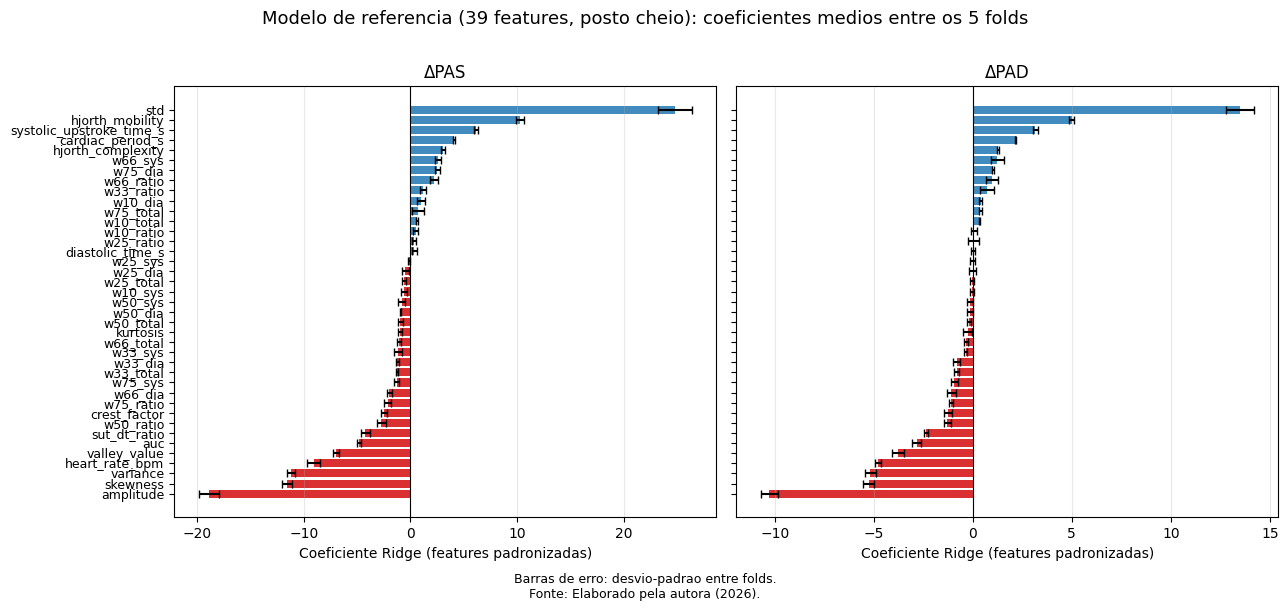

[figura] NB13_coeficientes_reduzido.png


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), sharey=True)
for ax, alvo in zip(axes, ["PAS", "PAD"]):
    sub = tab_coef[tab_coef.alvo == alvo].sort_values("coef_medio")
    cores = ["#d7191c" if v < 0 else "#2c7fb8" for v in sub.coef_medio]
    ax.barh(np.arange(len(sub)), sub.coef_medio, xerr=sub.coef_sd,
            color=cores, alpha=.9, capsize=3)
    ax.set_yticks(np.arange(len(sub))); ax.set_yticklabels(sub.feature, fontsize=9)
    ax.axvline(0, color="black", lw=.8)
    ax.set_xlabel("Coeficiente Ridge (features padronizadas)")
    ax.set_title(f"Δ{alvo}"); ax.grid(alpha=.3, axis="x")
fig.suptitle(f"Modelo de referencia ({len(REDUZIDO39)} features, posto cheio): "
             f"coeficientes medios entre os 5 folds", y=1.01, fontsize=13)
fig.text(0.5, -0.04, "Barras de erro: desvio-padrao entre folds.\n"
                     "Fonte: Elaborado pela autora (2026).", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(PASTA_FIGS / "NB13_coeficientes_reduzido.png", dpi=300, bbox_inches="tight")
plt.show()
print("[figura] NB13_coeficientes_reduzido.png")

## 10. Conferência: extração corrigida vs extração antiga

Este notebook roda sobre a base **v3** (segmentação vale-a-vale). Os valores da coluna
"extração antiga" foram validados em análises anteriores sobre a base pico-a-pico; **espera-se**
que os R² mudem, já que 21 das 41 features passaram a medir o que o nome indica.

O que **não** pode mudar são os invariantes estruturais e os controles — esses sim são
verificados com `assert`: número de sujeitos, o baseline (que depende só dos rótulos de PA,
não das features) e o colapso da distribuição nula do teste de permutação.

In [25]:
def val(df, filtro, col):
    return float(df[filtro][col].iloc[0])

r_pri = res_principal
# (grandeza, valor nesta execucao (v3), valor na extracao ANTIGA, e' invariante?, tolerancia)
conferencia = [
    ("Sujeitos", float(N_SUJEITOS), 1293.0, True, 0.0),
    ("Segmentos", float(N_SEGMENTOS), 51719.0, False, 0.0),
    ("Implantacao R2 PAS",  val(r_pri, (r_pri.alvo=="PAS") & (r_pri.modelo=="Within LINEAR (Ridge)"), "R2"),  0.2783, False, 0.0),
    ("Implantacao R2 PAD",  val(r_pri, (r_pri.alvo=="PAD") & (r_pri.modelo=="Within LINEAR (Ridge)"), "R2"),  0.2228, False, 0.0),
    ("Implantacao MAE PAS", val(r_pri, (r_pri.alvo=="PAS") & (r_pri.modelo=="Within LINEAR (Ridge)"), "MAE"), 10.5553, False, 0.0),
    ("Implantacao MAE PAD", val(r_pri, (r_pri.alvo=="PAD") & (r_pri.modelo=="Within LINEAR (Ridge)"), "MAE"),  5.9262, False, 0.0),
    ("Baseline MAE PAS",    val(r_pri, (r_pri.alvo=="PAS") & (r_pri.modelo.str.contains("BASELINE")), "MAE"), 12.6390, True, 0.010),
    ("Baseline MAE PAD",    val(r_pri, (r_pri.alvo=="PAD") & (r_pri.modelo.str.contains("BASELINE")), "MAE"),  6.7960, True, 0.010),
    ("RF implantacao R2 PAS", val(r_pri, (r_pri.alvo=="PAS") & (r_pri.modelo=="Within RANDOM FOREST"), "R2"), 0.2492, False, 0.0),
    ("Referencia39 R2 PAS", float(res_red[res_red.alvo=="PAS"].R2.iloc[0]),
     float(res_principal[(res_principal.alvo=="PAS") &
           (res_principal.modelo=="Within LINEAR (Ridge)")].R2.iloc[0]), True, 0.002),
    ("Referencia39 R2 PAD", float(res_red[res_red.alvo=="PAD"].R2.iloc[0]),
     float(res_principal[(res_principal.alvo=="PAD") &
           (res_principal.modelo=="Within LINEAR (Ridge)")].R2.iloc[0]), True, 0.002),
    ("Ablacao so FC PAS", float(res_abl[res_abl.conjunto=="SO frequencia cardiaca"].R2_PAS.iloc[0]), -0.0018, False, 0.0),
    # PTT-PPG agora roda sobre a base v3 (Secao 6). Comparado ao valor v2 (pico-a-pico); mudou -> esperado mudar.
    ("PTT-PPG R2 PAS (v3)", val(res_ptt, (res_ptt.alvo=="PAS") & res_ptt.modelo.str.contains("Within"), "R2"), -7.0710, False, 0.0),
    ("PTT-PPG R2 PAD (v3)", val(res_ptt, (res_ptt.alvo=="PAD") & res_ptt.modelo.str.contains("Within"), "R2"), -9.0006, False, 0.0),
    ("Gap 0 R2 PAS",  float(res_gap[res_gap.variante=="gap = 0 segmentos"].R2_PAS.iloc[0]),  0.2669, False, 0.0),
    ("Gap 10 R2 PAS", float(res_gap[res_gap.variante=="gap = 10 segmentos"].R2_PAS.iloc[0]), 0.2680, False, 0.0),
    ("Nula permutacao PAS (~0)", float(res_perm[res_perm.alvo=="PAS"].nula_media.iloc[0]), 0.0, True, 0.010),
    ("Nula permutacao PAD (~0)", float(res_perm[res_perm.alvo=="PAD"].nula_media.iloc[0]), 0.0, True, 0.010),
]

print(f"{'grandeza':<28s}{'v3 (corrigida)':>16s}{'antiga':>11s}{'delta':>10s}   tipo")
falhas = []
for nome, novo, antigo, invariante, tol in conferencia:
    d = novo - antigo
    if invariante:
        ok = abs(d) <= tol
        tipo = "INVARIANTE OK" if ok else "INVARIANTE FALHOU"
        if not ok:
            falhas.append((nome, novo, antigo, abs(d)))
    else:
        tipo = "esperado mudar"
    print(f"{nome:<28s}{novo:>16.4f}{antigo:>11.4f}{d:>+10.4f}   {tipo}")

pd.DataFrame(conferencia, columns=["grandeza", "v3_corrigida", "extracao_antiga",
                                   "invariante", "tolerancia"]).to_csv(
    PASTA_PULSEDB_FEAT / f"{PREFIXO}conferencia.csv", index=False)

print(f"\n{'='*70}")
assert not falhas, f"INVARIANTE VIOLADO em: {[f[0] for f in falhas]}"
print("INVARIANTES CONFEREM (sujeitos, baselines, nula da permutacao).")
print("O contraste PTT-PPG passou de v2 (-7.07/-9.00) para v3 (vale-a-vale) — ver Secao 6.")
print("Os R2 mudaram porque 21 das 41 features foram corrigidas — ver Notebook 14.")
print(f"{'='*70}")
print(f"\nNotebook 13 concluido em: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}")

grandeza                      v3 (corrigida)     antiga     delta   tipo
Sujeitos                           1293.0000  1293.0000   +0.0000   INVARIANTE OK
Segmentos                         51720.0000 51719.0000   +1.0000   esperado mudar
Implantacao R2 PAS                    0.2663     0.2783   -0.0120   esperado mudar
Implantacao R2 PAD                    0.2366     0.2228   +0.0138   esperado mudar
Implantacao MAE PAS                  10.7185    10.5553   +0.1632   esperado mudar
Implantacao MAE PAD                   5.9198     5.9262   -0.0064   esperado mudar
Baseline MAE PAS                     12.6384    12.6390   -0.0006   INVARIANTE OK
Baseline MAE PAD                      6.7956     6.7960   -0.0004   INVARIANTE OK
RF implantacao R2 PAS                 0.2456     0.2492   -0.0036   esperado mudar
Referencia39 R2 PAS                   0.2663     0.2663   +0.0000   INVARIANTE OK
Referencia39 R2 PAD                   0.2367     0.2366   +0.0000   INVARIANTE OK
Ablacao so FC PAS  

## 11. Síntese

**Existe sinal intra-sujeito recuperável no PulseDB (VitalDB).** No protocolo de implantação,
sem vazamento algum, o modelo explica **R² ≈ 0,27 (ΔPAS)** e **≈ 0,24 (ΔPAD)** da variação de PA
dentro do sujeito, reduzindo o MAE em ~1,9 mmHg (PAS) e ~0,9 mmHg (PAD) sobre o baseline de
repetir a média de calibração. O intervalo de confiança agrupado por sujeito não inclui zero,
e o controle negativo com 1.000 permutações colapsa a nula para ~0.

O resultado é **robusto à correção da segmentação**: com a extração antiga (pico-a-pico,
21 features degeneradas) obtinha-se R² 0,2783 / 0,2228; com a extração corrigida do
Notebook 14, 0,2663 / 0,2366. A magnitude e a conclusão não mudam — o que confirma que o sinal
vinha das features íntegras (amplitude, estatísticas e Hjorth), e não da morfologia
sístole/diástole que estava quebrada.

**No PTT-PPG não existe.** O mesmo pipeline dá R² fortemente negativo — pior que repetir a média
do sujeito — em **ambas** as extrações (v2 pico-a-pico e v3 vale-a-vale do Notebook 15). A
diferença não é de método: é da estrutura do rótulo. Uma leitura de manguito por registro não
tem variância intra-condição para se regredir. A própria instabilidade do R² entre extrações
(ΔPAS −7,07 → −1,72; ΔPAD −9,00 → −24,25) confirma o diagnóstico: com 57–66 unidades
sujeito×condição contra 41 preditores, o modelo está superparametrizado, e o R² de teste mede o
comportamento do overfitting, não sinal — ao contrário do PulseDB, cujo R² é estável sob a mesma
correção (0,2783 → 0,2663) porque há sinal ancorando o resultado.

**Ressalvas que devem acompanhar o resultado:**

1. **Clinicamente insuficiente para PAS.** O SD do erro permanece bem acima do limite AAMI de
   8 mmHg. O resultado é cientificamente válido, não um estimador utilizável.
2. **Ridge ≈ Random Forest.** Um modelo não-linear não extrai nada além da regressão linear
   regularizada — as features estáticas saturaram. Ganhos adicionais exigem *informação*
   diferente (dinâmica temporal da forma de onda), não mais capacidade de modelo.
3. **População única.** Apenas VitalDB (cirúrgica). Sem MIMIC-III, a generalização para UTI
   não foi testada.
4. **Sem eixo de tempo real.** A validade temporal da calibração só pôde ser avaliada em
   distância ordinal de segmentos.
5. **A base de 41 features é singular** (posto 40 de 41, nº de condição ≈ 5,96×10¹⁶), por conta de
   uma única identidade algébrica: `amplitude = peak_value − valley_value`. Para ler
   coeficientes, use o **modelo de referência de 39 features** da Seção 9 — posto cheio, mesmo
   R², e nenhuma feature descartada além das duas redundâncias exatas.

**Redundâncias remanescentes.** Mesmo após a correção, `hjorth_activity` continua idêntica a
`variance` (a *activity* de Hjorth **é** a variância, por definição) e `amplitude` =
`peak_value − valley_value`. São duas identidades algébricas do extrator, não propriedades do
sinal — removê-las é o que basta para restaurar o posto cheio. Note ainda que `std` e `variance`
são a mesma grandeza sob transformação não-linear (`variance = std²`): sobrevivem ao teste de
posto, mas formam um termo quadrático, não dois efeitos independentes.

**Alcance da correção da segmentação.** O defeito corrigido pelo Notebook 14 afetava 21 das 41
features e estava presente também no PTT-PPG (`_features_v2_clean.csv`, 44,2% dos ciclos com
`systolic_upstroke_time_s = 0`). O **Notebook 15** já re-extraiu o PTT-PPG vale-a-vale
(`_features_v3_clean.csv`), e a Seção 6 deste notebook passou a usá-lo no contraste. Os Notebooks
**03, 05, 06 e 11** ainda usam a extração antiga; seus resultados continuam válidos para os dados
que efetivamente processaram, mas as features de sístole/diástole neles **não medem o que o nome
indica**. As contagens de features das Versões A/B/C (43/41/35) superestimam o número de
variáveis informativas. Re-executar a cadeia 03→06 sobre a base v3 é a pendência natural
seguinte.